C:\Users\Nishad\AppData\Local\Temp\ipykernel_39116\63160624.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Nishad\AppData\Local\Temp\ipykernel_39116\63160624.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


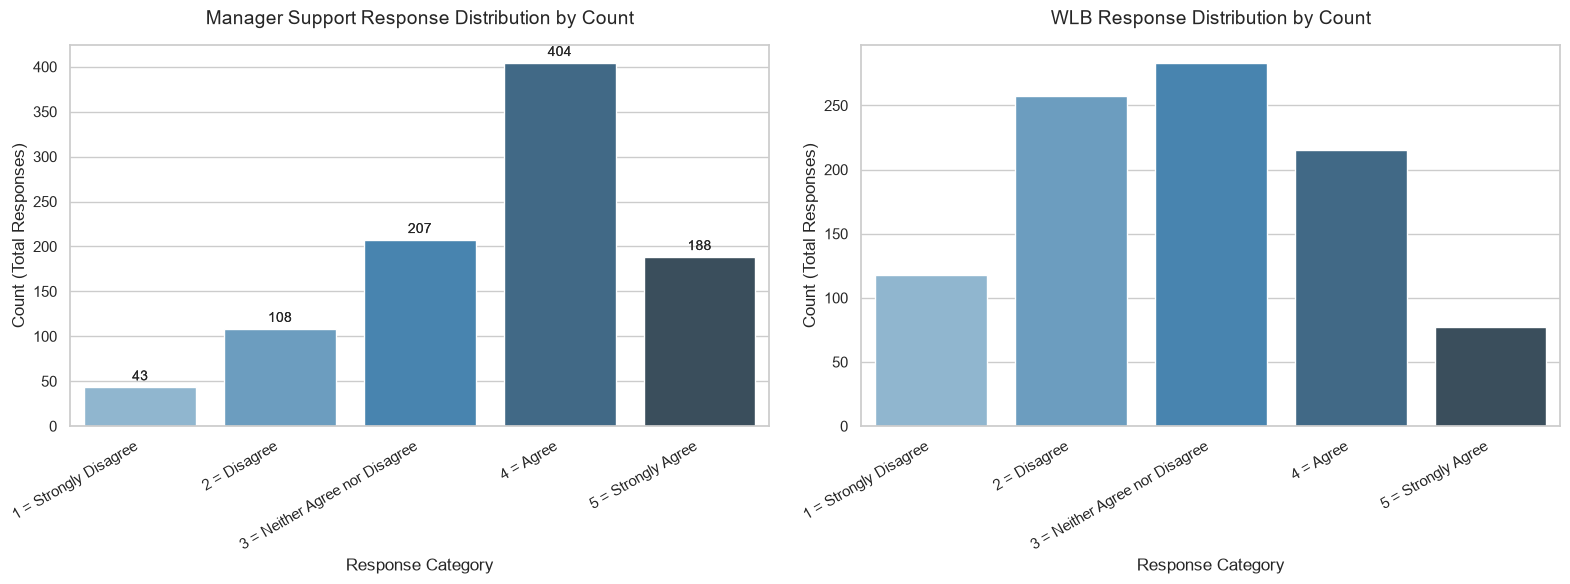

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Prepare the dataset
data = {
    'Response Category': [
        '1 = Strongly Disagree', 
        '2 = Disagree', 
        '3 = Neither Agree nor Disagree', 
        '4 = Agree', 
        '5 = Strongly Agree'
    ],
    'Count': [43, 108, 207, 404, 188],
}

data_1 = {
    'Response Category': [
        '1 = Strongly Disagree', 
        '2 = Disagree', 
        '3 = Neither Agree nor Disagree', 
        '4 = Agree', 
        '5 = Strongly Agree'
    ],
    'Count': [118,257,283,215,77],
}

df = pd.DataFrame(data)
df_1=pd.DataFrame(data_1)

# Set the visualization style
sns.set_theme(style="whitegrid")

# 2. Initialize side-by-side independent subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

# --- Left Chart: Count ---
sns.barplot(
    data=df, 
    x='Response Category', 
    y='Count', 
    ax=axes[0], 
    palette='Blues_d'
)
axes[0].set_title('Manager Support Response Distribution by Count', fontsize=14, pad=15)
axes[0].set_xlabel('Response Category', fontsize=12)
axes[0].set_ylabel('Count (Total Responses)', fontsize=12)

# Add value labels on top of the count bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, fontsize=10)

# --- Right Chart: Percentage (%) ---
# --- Left Chart: Count ---
sns.barplot(
    data=df_1, 
    x='Response Category', 
    y='Count', 
    ax=axes[1], 
    palette='Blues_d'
)
axes[1].set_title('WLB Response Distribution by Count', fontsize=14, pad=15)
axes[1].set_xlabel('Response Category', fontsize=12)
axes[1].set_ylabel('Count (Total Responses)', fontsize=12)

# Add value labels on top of the count bars
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, fontsize=10)
# 3. Clean up layout aesthetics
plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()


In [4]:
# Build cumulative frequency and percentage tables

def cumulative_table(source):
    table = source.copy()
    table['Cumulative Frequency'] = table['Count'].cumsum()
    table['Percentage (%)'] = table['Count'] / table['Count'].sum() * 100
    table['Cumulative Percentage (%)'] = table['Percentage (%)'].cumsum()

    return table[
        [
            'Response Category',
            'Count',
            'Percentage (%)',
            'Cumulative Percentage (%)'
        ]
    ].round({'Percentage (%)': 2, 'Cumulative Percentage (%)': 2})


manager_support_table = cumulative_table(df)
work_life_balance_table = cumulative_table(df_1)

print("                              Manager Support")
display(manager_support_table)

print("                              Work-Life Balance")
display(work_life_balance_table)

                              Manager Support


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 = Strongly Disagree,43,4.53,4.53
1,2 = Disagree,108,11.37,15.89
2,3 = Neither Agree nor Disagree,207,21.79,37.68
3,4 = Agree,404,42.53,80.21
4,5 = Strongly Agree,188,19.79,100.00


                              Work-Life Balance


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 = Strongly Disagree,118,12.42,12.42
1,2 = Disagree,257,27.05,39.47
2,3 = Neither Agree nor Disagree,283,29.79,69.26
3,4 = Agree,215,22.63,91.89
4,5 = Strongly Agree,77,8.11,100.00


C:\Users\Nishad\AppData\Local\Temp\ipykernel_39116\3748843427.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(manager_support, vert=True, patch_artist=True, widths=0.5)
C:\Users\Nishad\AppData\Local\Temp\ipykernel_39116\3748843427.py:20: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(work_life_balance, vert=True, patch_artist=True, widths=0.5)


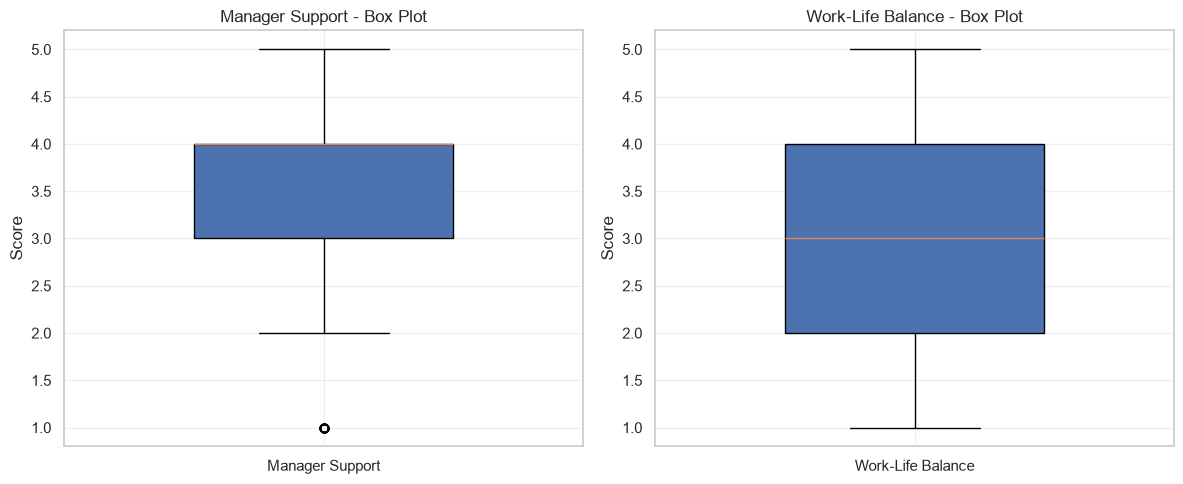

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Use the arrays already created from the response counts
manager_support = np.repeat([1, 2, 3, 4, 5], data['Count'])
work_life_balance = np.repeat([1, 2, 3, 4, 5], data_1['Count'])

# Create side-by-side box plots for Manager Support and Work-Life Balance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot for Manager Support
axes[0].boxplot(manager_support, vert=True, patch_artist=True, widths=0.5)
axes[0].set_ylabel('Score')
axes[0].set_title('Manager Support - Box Plot')
axes[0].set_xticks([1])
axes[0].set_xticklabels(['Manager Support'])
axes[0].grid(True, alpha=0.3)

# Box plot for Work-Life Balance
axes[1].boxplot(work_life_balance, vert=True, patch_artist=True, widths=0.5)
axes[1].set_ylabel('Score')
axes[1].set_title('Work-Life Balance - Box Plot')
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Work-Life Balance'])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# Compare distribution summary statistics
comparison_table = pd.DataFrame({
    'Measure': [
        'Median',
        'Interquartile Interval (Q1–Q3)',
        'Bottom-Two-Box (%)',
        'Top-Two-Box (%)'
    ],
    'Manager Support': [
        np.median(manager_support),
        f"{np.percentile(manager_support, 25):.2f}–{np.percentile(manager_support, 75):.2f}",
        (np.mean(manager_support <= 2) * 100),
        (np.mean(manager_support >= 4) * 100)
    ],
    'Work-Life Balance': [
        np.median(work_life_balance),
        f"{np.percentile(work_life_balance, 25):.2f}–{np.percentile(work_life_balance, 75):.2f}",
        (np.mean(work_life_balance <= 2) * 100),
        (np.mean(work_life_balance >= 4) * 100)
    ]
})

comparison_table['Manager Support'] = comparison_table['Manager Support'].apply(
    lambda value: f"{value:.2f}%" if isinstance(value, (int, float, np.number)) and '%' in comparison_table.loc[
        comparison_table['Manager Support'] == value, 'Measure'
    ].iloc[0] else value
)

display(comparison_table)

,Measure,Manager Support,Work-Life Balance
0,Median,4.0,3.0
1,Interquartile Interval (Q1–Q3),3.00–4.00,2.00–4.00
2,Bottom-Two-Box (%),15.89%,39.473684
3,Top-Two-Box (%),62.32%,30.736842


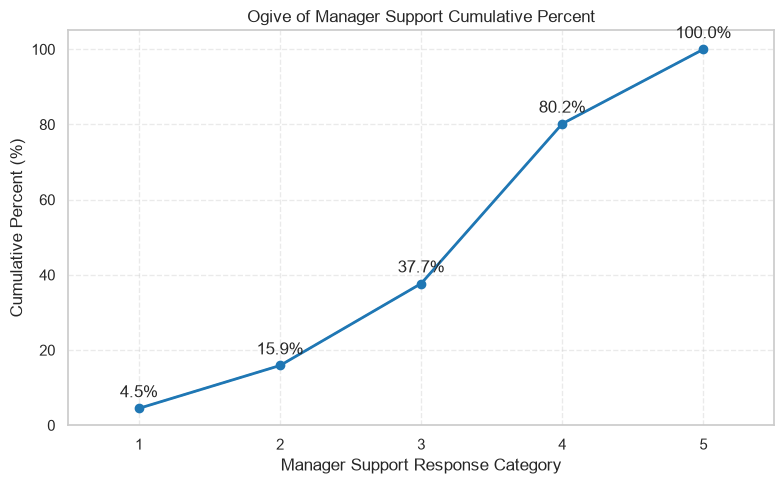

In [7]:
# Ogive for cumulative percent of manager support responses
scores = [1, 2, 3, 4, 5]
cumulative_pct = [4.5, 15.9, 37.7, 80.2, 100.0]

plt.figure(figsize=(8, 5))
plt.plot(scores, cumulative_pct, marker='o', linestyle='-', linewidth=2, color='tab:blue')
plt.plot(scores, cumulative_pct, linestyle='--', alpha=0.5, color='tab:blue')

plt.xticks(scores)
plt.yticks([0, 20, 40, 60, 80, 100])
plt.xlim(0.5, 5.5)
plt.ylim(0, 105)

plt.xlabel('Manager Support Response Category')
plt.ylabel('Cumulative Percent (%)')
plt.title('Ogive of Manager Support Cumulative Percent')
plt.grid(True, linestyle='--', alpha=0.4)

for x, y in zip(scores, cumulative_pct):
    plt.annotate(f'{y}%', (x, y), textcoords='offset points', xytext=(0, 8), ha='center')

plt.tight_layout()
plt.show()

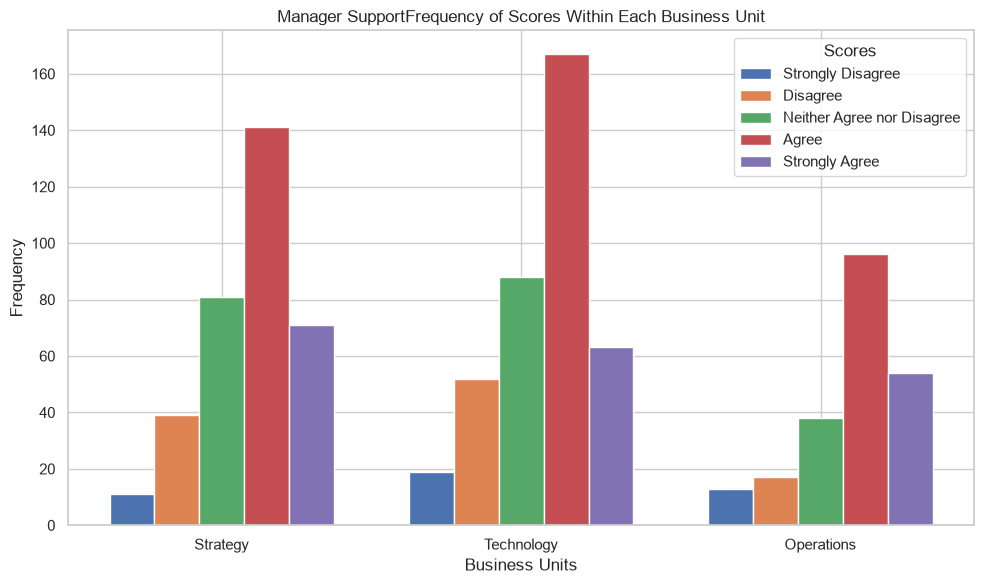

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Data setup
business_units = ['Strategy', 'Technology', 'Operations']

# Frequency arrays grouped by score (Score 1 data for all 3 units, Score 2 data, etc.)
score_1 = [11, 19, 13]
score_2 = [39, 52, 17]
score_3 = [81, 88, 38]
score_4 = [141, 167, 96]
score_5 = [71, 63, 54]

x = np.arange(len(business_units))  # Label locations for the 3 business units
width = 0.15  # Width of each individual bar

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the 5 grouped bars for each business unit
ax.bar(x - 2 * width, score_1, width, label='Strongly Disagree')
ax.bar(x - width, score_2, width, label='Disagree')
ax.bar(x, score_3, width, label='Neither Agree nor Disagree')
ax.bar(x + width, score_4, width, label='Agree')
ax.bar(x + 2 * width, score_5, width, label='Strongly Agree')

# Add labels, titles, and layout configurations
ax.set_xlabel('Business Units')
ax.set_ylabel('Frequency')
ax.set_title('Manager SupportFrequency of Scores Within Each Business Unit')
ax.set_xticks(x)
ax.set_xticklabels(business_units)
ax.legend(title="Scores")

plt.tight_layout()
plt.show()


In [20]:

manager_support_counts = pd.DataFrame(
    {
        'Strongly Disagree': score_1,
        'Disagree': score_2,
        'Neither Agree nor Disagree': score_3,
        'Agree': score_4,
        'Strongly Agree': score_5
    },
    index=business_units
)

manager_support_row_percentages = (
    manager_support_counts.div(manager_support_counts.sum(axis=1), axis=0) * 100
).round(2)

manager_support_row_percentages.index.name = 'Business Unit'

display(manager_support_row_percentages)

,Strongly Disagree,Disagree,Neither Agree nor Disagree,Agree,Strongly Agree
Business Unit,,,,,
Strategy,3.21,11.37,23.62,41.11,20.70
Technology,4.88,13.37,22.62,42.93,16.20
Operations,5.96,7.80,17.43,44.04,24.77


In [10]:
# Display separate tables for each business unit

for unit in manager_support_counts.index:
    counts = manager_support_counts.loc[unit]
    total = counts.sum()

    unit_table = pd.DataFrame({
        'Response Category': counts.index,
        'Count': counts.values,
        'Percentage (%)': (counts.values / total * 100).round(2),
        'Cumulative Percentage (%)': (
            counts.cumsum().values / total * 100
        ).round(2)
    }).reset_index(drop=True)

    responses = np.repeat(score_values, counts.values)

    print(f"{unit}")
    display(unit_table)

    print(f"Median: {np.median(responses):.2f}")
    print(f"Top-Two-Box (%): {np.mean(responses >= 4) * 100:.2f}%")
    print("-" * 60)


Strategy


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,Strongly Disagree,11,3.21,3.21
1,Disagree,39,11.37,14.58
2,Neither Agree nor Disagree,81,23.62,38.19
3,Agree,141,41.11,79.30
4,Strongly Agree,71,20.70,100.00


Median: 4.00
Top-Two-Box (%): 61.81%
------------------------------------------------------------
Technology


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,Strongly Disagree,19,4.88,4.88
1,Disagree,52,13.37,18.25
2,Neither Agree nor Disagree,88,22.62,40.87
3,Agree,167,42.93,83.80
4,Strongly Agree,63,16.20,100.00


Median: 4.00
Top-Two-Box (%): 59.13%
------------------------------------------------------------
Operations


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,Strongly Disagree,13,5.96,5.96
1,Disagree,17,7.80,13.76
2,Neither Agree nor Disagree,38,17.43,31.19
3,Agree,96,44.04,75.23
4,Strongly Agree,54,24.77,100.00


Median: 4.00
Top-Two-Box (%): 68.81%
------------------------------------------------------------


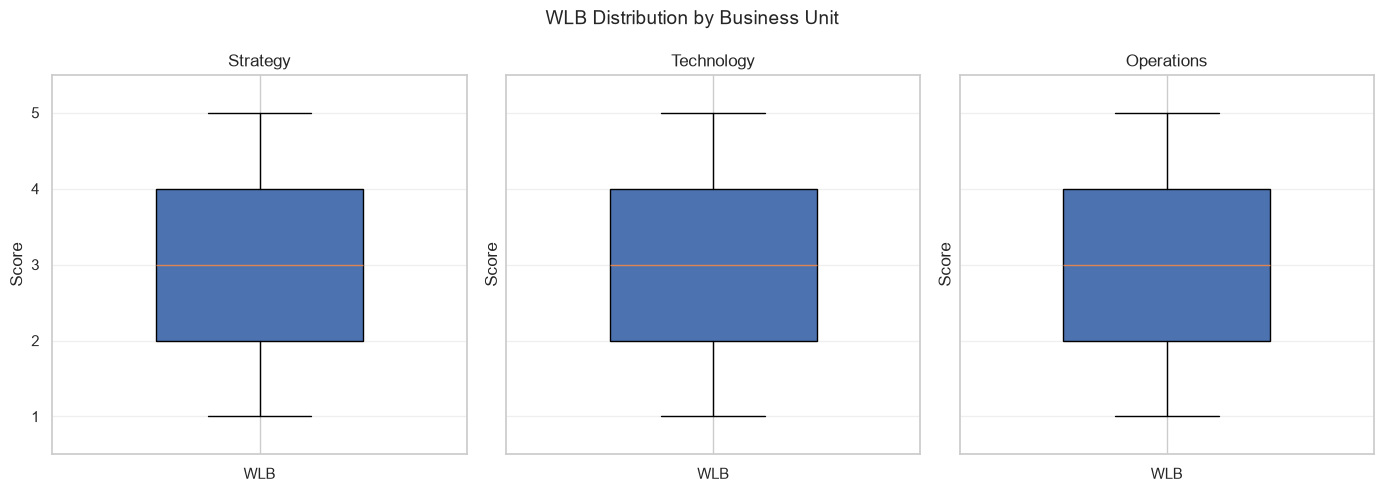

In [15]:
import numpy as np
import matplotlib.pyplot as plt

score_values = np.array([1, 2, 3, 4, 5])

unit_responses = {
    unit: np.repeat(score_values, counts)
    for unit, counts in manager_support_counts.iterrows()
}

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

for ax, (unit, responses) in zip(axes, unit_responses.items()):
    ax.boxplot(responses, patch_artist=True, widths=0.5)
    ax.set_title(unit)
    ax.set_xticks([1])
    ax.set_xticklabels(['WLB'])
    ax.set_ylabel('Score')
    ax.set_ylim(0.5, 5.5)
    ax.set_yticks(score_values)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('WLB Distribution by Business Unit', fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
# Calculate IQV for the overall Manager Support and WLB distributions

def calculate_iqv(counts):
    k = len(counts)
    proportions = counts / counts.sum()
    return (k / (k - 1)) * (1 - (proportions ** 2).sum())

manager_support_iqv = calculate_iqv(df['Count'])
wlb_iqv = calculate_iqv(df_1['Count'])

iqv_table = pd.DataFrame({
    'Measure': ['Manager Support', 'Work-Life Balance'],
    'IQV': [manager_support_iqv, wlb_iqv]
})

iqv_table['IQV'] = iqv_table['IQV'].round(4)
display(iqv_table)

,Measure,IQV
0,Manager Support,0.8969
1,Work-Life Balance,0.9561


In [22]:
manager_support_counts

,Strongly Disagree,Disagree,Neither Agree nor Disagree,Agree,Strongly Agree
Business Unit,,,,,
Strategy,11,39,81,141,71
Technology,19,52,88,167,63
Operations,13,17,38,96,54


In [23]:
# Calculate business-unit-wise IQV for Manager Support

def calculate_iqv(counts):
    proportions = counts / counts.sum()
    k = len(counts)
    return (k / (k - 1)) * (1 - (proportions ** 2).sum())

business_unit_iqv = pd.DataFrame({
    'Business Unit': manager_support_counts.index,
    'IQV': manager_support_counts.apply(calculate_iqv, axis=1).round(4).values
})

display(business_unit_iqv)

,Business Unit,IQV
0,Strategy,0.8981
1,Technology,0.8975
2,Operations,0.8809


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

score_values = np.array([1, 2, 3, 4, 5])

unit_responses = {
    unit: np.repeat(score_values, counts)
    for unit, counts in manager_support_counts.iterrows()
}

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

for ax, (unit, responses) in zip(axes, unit_responses.items()):
    ax.boxplot(responses, patch_artist=True, widths=0.5)
    ax.set_title(unit)
    ax.set_xticks([1])
    ax.set_xticklabels(['Manager Support'])
    ax.set_ylabel('Score')
    ax.set_ylim(0.5, 5.5)
    ax.set_yticks(score_values)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Manager Support Distribution by Business Unit', fontsize=14)
plt.tight_layout()
plt.show()

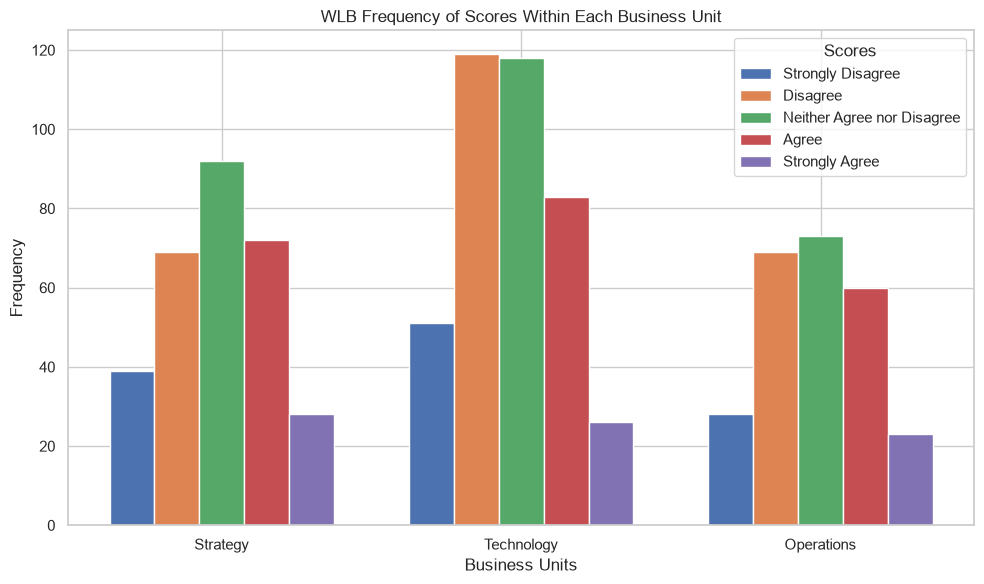

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Data setup
business_units = ['Strategy', 'Technology', 'Operations']

# Frequency arrays grouped by score (Score 1 data for all 3 units, Score 2 data, etc.)
score_1 = [39,51,28]
score_2 = [69,119,69]
score_3 = [92,118,73]
score_4 = [72,83,60]
score_5 = [28,26,23]

x = np.arange(len(business_units))  # Label locations for the 3 business units
width = 0.15  # Width of each individual bar

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the 5 grouped bars for each business unit
ax.bar(x - 2 * width, score_1, width, label='Strongly Disagree')
ax.bar(x - width, score_2, width, label='Disagree')
ax.bar(x, score_3, width, label='Neither Agree nor Disagree')
ax.bar(x + width, score_4, width, label='Agree')
ax.bar(x + 2 * width, score_5, width, label='Strongly Agree')

# Add labels, titles, and layout configurations
ax.set_xlabel('Business Units')
ax.set_ylabel('Frequency')
ax.set_title('WLB Frequency of Scores Within Each Business Unit')
ax.set_xticks(x)
ax.set_xticklabels(business_units)
ax.legend(title="Scores")

plt.tight_layout()
plt.show()


In [24]:
import pandas as pd

# Load your dataset
data = {
    'Employee ID': ['E317', 'E204', 'E589', 'E112', 'E451', 'E638', 'E923', 'E377', 'E745', 'E806', 'E619', 'E732', 'E584', 'E961', 'E428', 'E355', 'E794', 'E521', 'E688', 'E409'],
    'Manager Support (X)': [5, 2, 4, 1, 3, 4, 5, 2, 3, 4, 1, 2, 3, 4, 5, 2, 3, 4, 5, 3],
    'Work-Life Balance (Y)': [4, 2, 3, 1, 3, 2, 5, 3, 2, 4, 2, 1, 4, 3, 3, 3, 1, 4, 2, 3]
}

df = pd.DataFrame(data)

pearson_corr = df['Manager Support (X)'].corr(df['Work-Life Balance (Y)'])
spearman_corr = df['Manager Support (X)'].corr(df['Work-Life Balance (Y)'], method='spearman')

print(f"Pearson Correlation Coefficient: {pearson_corr:.4f}")
print(f"Spearman Correlation Coefficient: {spearman_corr:.4f}")


Pearson Correlation Coefficient: 0.5553
Spearman Correlation Coefficient: 0.5313


In [25]:
df

,Employee ID,Manager Support (X),Work-Life Balance (Y)
0,E317,5,4
1,E204,2,2
2,E589,4,3
3,E112,1,1
4,E451,3,3
5,E638,4,2
6,E923,5,5
7,E377,2,3
8,E745,3,2
9,E806,4,4


In [36]:
spearman_df = df[['Manager Support (X)', 'Work-Life Balance (Y)']].rename(
    columns={
        'Manager Support (X)': 'X',
        'Work-Life Balance (Y)': 'Y'
    }
).copy()

spearman_df['Rank(Xi)'] = spearman_df['X'].rank(method='average')
spearman_df['Rank(Yi)'] = spearman_df['Y'].rank(method='average')

spearman_rho = spearman_df['Rank(Xi)'].corr(spearman_df['Rank(Yi)'])
print(f"Spearman rank correlation: {spearman_rho:.4f}")

display(spearman_df)

Spearman rank correlation: 0.5313


,X,Y,Rank(Xi),Rank(Yi)
0,5,4,18.5,17.5
1,2,2,4.5,6.0
2,4,3,14.0,12.0
3,1,1,1.5,2.0
4,3,3,9.0,12.0
5,4,2,14.0,6.0
6,5,5,18.5,20.0
7,2,3,4.5,12.0
8,3,2,9.0,6.0
9,4,4,14.0,17.5


In [37]:
spearman_df.columns

Index(['X', 'Y', 'Rank(Xi)', 'Rank(Yi)'], dtype='object')

In [39]:
np.mean(spearman_df['Rank(Xi)'])

np.float64(10.5)

In [26]:
from itertools import combinations

x_vals = df["Manager Support (X)"].to_numpy()
y_vals = df["Work-Life Balance (Y)"].to_numpy()

concordant = 0
discordant = 0
tied = 0

for i, j in combinations(range(len(x_vals)), 2):
    dx = x_vals[i] - x_vals[j]
    dy = y_vals[i] - y_vals[j]

    if dx == 0 or dy == 0:
        tied += 1
    elif dx * dy > 0:
        concordant += 1
    elif dx * dy < 0:
        discordant += 1

print(f"Concordant pairs: {concordant}")
print(f"Discordant pairs: {discordant}")
print(f"Tied pairs: {tied}")

Concordant pairs: 95
Discordant pairs: 26
Tied pairs: 69


In [27]:
import numpy as np
from collections import Counter
from itertools import combinations

x = np.asarray(x_vals, dtype=float)
y = np.asarray(y_vals, dtype=float)

n = len(x)
concordant = 0
discordant = 0

for i, j in combinations(range(n), 2):
    dx = x[i] - x[j]
    dy = y[i] - y[j]

    if dx == 0 or dy == 0:
        continue
    elif dx * dy > 0:
        concordant += 1
    elif dx * dy < 0:
        discordant += 1

# Tie correction terms
x_counts = Counter(x.tolist())
y_counts = Counter(y.tolist())

T_x = sum(k * (k - 1) / 2 for k in x_counts.values())
T_y = sum(k * (k - 1) / 2 for k in y_counts.values())

n_c2 = n * (n - 1) / 2

denominator = np.sqrt((n_c2 - T_x) * (n_c2 - T_y))
tau_b = (concordant - discordant) / denominator if denominator != 0 else 0

print(f"Concordant pairs: {concordant}")
print(f"Discordant pairs: {discordant}")
print(f"Kendall's tau-b (with ties): {tau_b:.4f}")

Concordant pairs: 95
Discordant pairs: 26
Kendall's tau-b (with ties): 0.4496


In [35]:
print(T_x,T_y)

33.0 40.0


In [34]:
print(df["Manager Support (X)"].value_counts())
print(df["Work-Life Balance (Y)"].value_counts())

Manager Support (X)
4    5
3    5
5    4
2    4
1    2
Name: count, dtype: int64
Work-Life Balance (Y)
3    7
2    5
4    4
1    3
5    1
Name: count, dtype: int64


In [3]:
# Spearman rank correlation using average ranks for ties

import pandas as pd

rank_x = pd.Series(x).rank(method="average").to_numpy()
rank_y = pd.Series(y).rank(method="average").to_numpy()

rank_x_mean = rank_x.mean()
rank_y_mean = rank_y.mean()

rank_terms = pd.DataFrame({
    "x": x,
    "y": y,
    "Rank(X)": rank_x,
    "Rank(Y)": rank_y
})

rank_terms["Rank(X) - Mean Rank(X)"] = rank_x - rank_x_mean
rank_terms["Rank(Y) - Mean Rank(Y)"] = rank_y - rank_y_mean
rank_terms["Product of Deviations"] = (
    rank_terms["Rank(X) - Mean Rank(X)"]
    * rank_terms["Rank(Y) - Mean Rank(Y)"]
)
rank_terms["X Deviation Squared"] = (
    rank_terms["Rank(X) - Mean Rank(X)"] ** 2
)
rank_terms["Y Deviation Squared"] = (
    rank_terms["Rank(Y) - Mean Rank(Y)"] ** 2
)

display(rank_terms.round(4))

numerator = rank_terms["Product of Deviations"].sum()
denominator = np.sqrt(
    rank_terms["X Deviation Squared"].sum()
    * rank_terms["Y Deviation Squared"].sum()
)

spearman_rho = numerator / denominator

print(f"Mean rank of X: {rank_x_mean:.4f}")
print(f"Mean rank of Y: {rank_y_mean:.4f}")
print(f"Σ[(Rxi - R̄x)(Ryi - R̄y)]: {numerator:.4f}")
print(f"Σ(Rxi - R̄x)²: {rank_terms['X Deviation Squared'].sum():.4f}")
print(f"Σ(Ryi - R̄y)²: {rank_terms['Y Deviation Squared'].sum():.4f}")
print(f"Spearman rank correlation: {spearman_rho:.4f}")

,x,y,Rank(X),Rank(Y),Rank(X) - Mean Rank(X),Rank(Y) - Mean Rank(Y),Product of Deviations,X Deviation Squared,Y Deviation Squared
0,5,4,18.5,17.5,8.0,7.0,56.00,64.00,49.00
1,2,2,4.5,6.0,-6.0,-4.5,27.00,36.00,20.25
2,4,3,14.0,12.0,3.5,1.5,5.25,12.25,2.25
3,1,1,1.5,2.0,-9.0,-8.5,76.50,81.00,72.25
4,3,3,9.0,12.0,-1.5,1.5,-2.25,2.25,2.25
5,4,2,14.0,6.0,3.5,-4.5,-15.75,12.25,20.25
6,5,5,18.5,20.0,8.0,9.5,76.00,64.00,90.25
7,2,3,4.5,12.0,-6.0,1.5,-9.00,36.00,2.25
8,3,2,9.0,6.0,-1.5,-4.5,6.75,2.25,20.25
9,4,4,14.0,17.5,3.5,7.0,24.50,12.25,49.00


Mean rank of X: 10.5000
Mean rank of Y: 10.5000
Σ[(Rxi - R̄x)(Ryi - R̄y)]: 333.2500
Σ(Rxi - R̄x)²: 634.5000
Σ(Ryi - R̄y)²: 620.0000
Spearman rank correlation: 0.5313


In [7]:
rank_terms["Rank(X)"].value_counts()

Rank(X)
14.0    5
9.0     5
18.5    4
4.5     4
1.5     2
Name: count, dtype: int64

In [9]:
a=[11.3, 13.7, 14.2, 14.8, 15.1, 15.6, 15.9, 16.2, 16.5, 16.8, 17.4, 18.1, 19.3, 22.7, 26.4, 31.8]
q1, q3 = np.percentile(a, [25, 75])
print(f"First quartile (Q1): {q1}")
print(f"Third quartile (Q3): {q3}")

First quartile (Q1): 15.025
Third quartile (Q3): 18.400000000000002


In [8]:
arr=(43.2, 46.7, 48.1, 51.4, 53.8, 55.2, 58.9, 63.4, 71.7, 97.6)
# Third moment about the mean (central third moment)
arr_array = np.asarray(arr)
mean_val = arr_array.mean()
third_moment = np.mean((arr_array - mean_val) ** 3)

# Also show the raw third moment for comparison
raw_third_moment = np.mean(arr_array ** 3)

print(f"Mean: {mean_val}")
print(f"3rd central moment: {third_moment}")
print(f"3rd raw moment: {raw_third_moment}")

Mean: 59.0
3rd central moment: 5191.135799999998
3rd raw moment: 251096.05580000003


In [1]:
x=[5, 2, 4, 1, 3, 4, 5, 2, 3, 4, 1, 2, 3, 4, 5, 2, 3, 4, 5, 3]
y= [4, 2, 3, 1, 3, 2, 5, 3, 2, 4, 2, 1, 4, 3, 3, 3, 1, 4, 2, 3]
average_x = sum(x) / len(x)
average_y = sum(y) / len(y)

x_sq= [i**2 for i in x]
y_sq= [i**2 for i in y]
print(average_x) 
print(average_y)  
print(sum(x_sq))
print(sum(y_sq))

import numpy as np
var = np.var(x)
var_y = np.var(y)

print(var)
print(var_y)

xy=[i*j for i,j in zip(x,y)]
sum_xy=sum(xy)
print(sum_xy)

# matrix = np.cov(x, y)

# # Extract the specific cross-covariance value
# covariance_val = matrix[0, 1]

# print("Covariance Matrix:\n", matrix)
# print("Cross-Covariance:", covariance_val)


3.25
2.75
243
175
1.5875
1.1875
194


### investwise

In [8]:
import pandas as pd

# Combined data from all three blocks in the image
data = {
    "Month": list(range(1, 37)),
    "Fund_Yi": [
        2.3, -1.2, 4.5, 1.8, -0.7, 3.2, 2.6, 1.4, -3.5, 2.0, 0.8, 5.8,   # Months 1-12
        1.5, 3.1, -2.1, 2.9, 1.1, 4.7, -1.8, 2.4, 0.6, 3.9, 1.9, -0.3,  # Months 13-24
        0.9, 2.8, 1.7, -0.5, 3.3, 2.1, 1.4, 5.2, -1.1, 2.5, 1.0, 3.7   # Months 25-36
    ],
    "SP500_Xi": [
        1.8, -0.8, 3.6, 1.5, -0.5, 2.5, 2.0, 1.1, -2.8, 1.6, 0.6, 4.5,   # Months 1-12
        1.2, 2.4, -1.5, 2.3, 0.9, 3.8, -1.3, 1.9, 0.5, 3.1, 1.5, -0.2,  # Months 13-24
        0.7, 2.1, 1.3, -0.3, 2.7, 1.6, 1.1, 4.1, -0.9, 2.0, 0.8, 2.9   # Months 25-36
    ]
}

# Create the DataFrame
df = pd.DataFrame(data)

# Optional: Set the Month column as the index
df.set_index("Month", inplace=True)

df.head()
#36-Month Historical Monthly Returns (%) for InvestWise Portfolio and S&P 500 Index

,Fund_Yi,SP500_Xi
Month,,
1,2.3,1.8
2,-1.2,-0.8
3,4.5,3.6
4,1.8,1.5
5,-0.7,-0.5


In [9]:
from scipy.stats import trim_mean

trim_proportion = 0.10

fund_returns = df["Fund_Yi"]
sp500_returns = df["SP500_Xi"]

# Geometric mean return using growth factors
fund_geometric_mean = (
    np.prod(1 + fund_returns / 100) ** (1 / len(fund_returns)) - 1
) * 100

sp500_geometric_mean = (
    np.prod(1 + sp500_returns / 100) ** (1 / len(sp500_returns)) - 1
) * 100

# 10% trimmed arithmetic means
fund_trimmed_mean = trim_mean(fund_returns, proportiontocut=trim_proportion)
sp500_trimmed_mean = trim_mean(sp500_returns, proportiontocut=trim_proportion)

results = pd.DataFrame({
    "Measure": [
        "Geometric Mean Return (%)",
        "10% Trimmed Mean Return (%)"
    ],
    "Fund": [
        fund_geometric_mean,
        fund_trimmed_mean
    ],
    "S&P 500": [
        sp500_geometric_mean,
        sp500_trimmed_mean
    ]
})

display(results.round(4))

,Measure,Fund,S&P 500
0,Geometric Mean Return (%),1.6426,1.3148
1,10% Trimmed Mean Return (%),1.7200,1.3667


In [10]:
# Median absolute deviation from the median (MADFM)

madfm = (df - df.median()).abs().median()

print("Median absolute deviation from the median:")
display(madfm.to_frame(name="MADFM").round(4))

Median absolute deviation from the median:


,MADFM
Fund_Yi,1.15
SP500_Xi,0.90


In [11]:
# Quartiles and 1.5 × IQR outlier detection

for column in ["Fund_Yi", "SP500_Xi"]:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_fence) | (df[column] > upper_fence)
    ]

    print(f"\n{column}")
    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower fence: {lower_fence:.2f}")
    print(f"Upper fence: {upper_fence:.2f}")
    print("Outlier months and returns:")
    print(outliers[[column]])

print("\nInterpretation:")
print(
    "Month 9 is a statistical outlier because its negative return falls below "
    "the lower 1.5×IQR fence for both the fund and the S&P 500."
)
print(
    "Month 12 is not an outlier because its high positive return remains within "
    "the upper fence. It reflects the expected dispersion of returns."
)
print(
    "Because Month 9 is also extreme for the S&P 500, it likely reflects a "
    "broader market movement rather than fund-specific sector allocations alone."
)


Fund_Yi
Q1: 0.75
Q3: 2.95
IQR: 2.20
Lower fence: -2.55
Upper fence: 6.25
Outlier months and returns:
       Fund_Yi
Month         
9         -3.5

SP500_Xi
Q1: 0.57
Q3: 2.32
IQR: 1.75
Lower fence: -2.05
Upper fence: 4.95
Outlier months and returns:
       SP500_Xi
Month          
9          -2.8

Interpretation:
Month 9 is a statistical outlier because its negative return falls below the lower 1.5×IQR fence for both the fund and the S&P 500.
Month 12 is not an outlier because its high positive return remains within the upper fence. It reflects the expected dispersion of returns.
Because Month 9 is also extreme for the S&P 500, it likely reflects a broader market movement rather than fund-specific sector allocations alone.


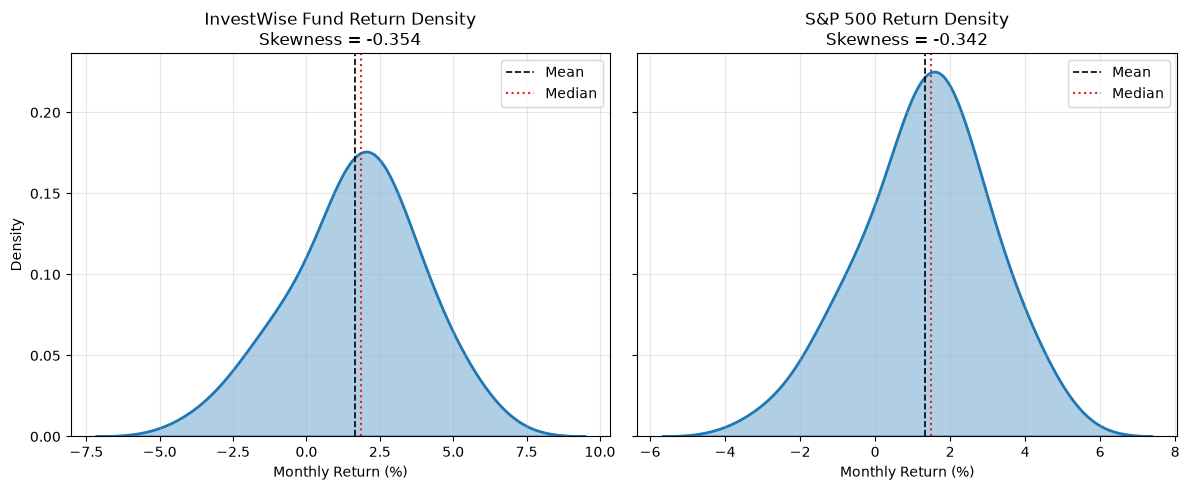

In [12]:
import seaborn as sns

import matplotlib.pyplot as plt

# Compute skewness to support the visual interpretation
skew_fund = df["Fund_Yi"].skew()
skew_sp500 = df["SP500_Xi"].skew()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col, label, skew_val in [
    (axes[0], "Fund_Yi", "InvestWise Fund", skew_fund),
    (axes[1], "SP500_Xi", "S&P 500", skew_sp500),
]:
    sns.kdeplot(
        df[col],
        ax=ax,
        fill=True,
        alpha=0.35,
        linewidth=2,
        bw_adjust=1.2,
        color="tab:blue"
    )
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.2, label="Mean")
    ax.axvline(df[col].median(), color="tab:red", linestyle=":", linewidth=1.5, label="Median")
    ax.set_title(f"{label} Return Density\nSkewness = {skew_val:.3f}")
    ax.set_xlabel("Monthly Return (%)")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [13]:
# Calculate alpha, beta, R-squared, and correlation
X = df["SP500_Xi"].to_numpy()
Y = df["Fund_Yi"].to_numpy()

# Regression model: Fund return = alpha + beta × S&P 500 return
beta, alpha = np.polyfit(X, Y, 1)

predicted_Y = alpha + beta * X
residuals = Y - predicted_Y

ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((Y - Y.mean()) ** 2)

r_squared = 1 - (ss_res / ss_tot)
correlation = np.corrcoef(X, Y)[0, 1]

print(f"Alpha (intercept): {alpha:.4f}")
print(f"Beta (slope): {beta:.4f}")
print(f"R-squared: {r_squared:.4f}")
print(f"Correlation: {correlation:.4f}")

Alpha (intercept): -0.0385
Beta (slope): 1.2821
R-squared: 0.9988
Correlation: 0.9994


In [4]:
fund_std = df["Fund_Yi"].std(ddof=0)
sp500_std = df["SP500_Xi"].std(ddof=0)

print(f"Fund standard deviation: {fund_std:.4f}")
print(f"S&P 500 standard deviation: {sp500_std:.4f}")

Fund standard deviation: 2.0751
S&P 500 standard deviation: 1.6175


In [ ]:
fund_std = df["Fund_Yi"].std()
sp500_std = df["SP500_Xi"].std()

print(f"Fund standard deviation: {fund_std:.4f}")
print(f"S&P 500 standard deviation: {sp500_std:.4f}")

Fund standard deviation: 2.1046
S&P 500 standard deviation: 1.6405


In [6]:
# Mean absolute deviation about the median
mad_about_median = (
    df.subtract(df.median())
      .abs()
      .mean()
)

print("Mean absolute deviation about the median:")
print(mad_about_median)

Mean absolute deviation about the median:
Fund_Yi     1.608333
SP500_Xi    1.250000
dtype: float64


In [ ]:
# Summary statistics using N as the normalization denominator

summary_table = pd.DataFrame(index=df.columns)

summary_table["Mean"] = df.mean()
summary_table["Median"] = df.median()
summary_table["Variance"] = df.var(ddof=0)
summary_table["Standard Deviation"] = df.std(ddof=0)
summary_table["Mean Absolute Deviation about Median"] = (
    df.subtract(df.median()).abs().mean()m
)

display(summary_table.round(4))

,Mean,Median,Variance,Standard Deviation,Mean Absolute Deviation about Median
Fund_Yi,1.6639,1.85,4.3062,2.0751,1.6083
SP500_Xi,1.3278,1.50,2.6165,1.6175,1.2500


In [5]:
2.1046*2.1046

4.42934116

In [49]:
# Mean returns and volatility
fund_mean = np.mean(df["Fund_Yi"])
sp500_mean = np.mean(df["SP500_Xi"])
fund_volatility = np.std(df["Fund_Yi"], ddof=1)  # sample standard deviation

# Beta of the fund relative to the S&P 500
# Beta = Cov(Fund, Market) / Var(Market)
cov_xy = np.cov(df["Fund_Yi"], df["SP500_Xi"], ddof=1)[0, 1]
var_x = np.var(df["SP500_Xi"], ddof=1)
beta = cov_xy / var_x

# If the market return is +1 (i.e., 1 percentage point/unit), expected fund move:
expected_fund_change = beta * 1

print(f"Mean Fund Return (Fund_Yi): {fund_mean:.4f}")
print(f"Mean S&P 500 Return (SP500_Xi): {sp500_mean:.4f}")
print(f"Fund Volatility (Std Dev): {fund_volatility:.4f}")
print(f"Beta of Fund vs S&P 500: {beta:.4f}")
print(f"If SP500 return = 1, expected Fund return change = {expected_fund_change:.4f}")


Mean Fund Return (Fund_Yi): 1.6639
Mean S&P 500 Return (SP500_Xi): 1.3278
Fund Volatility (Std Dev): 2.1046
Beta of Fund vs S&P 500: 1.2821
If SP500 return = 1, expected Fund return change = 1.2821


In [ ]:
#mean absolute difference

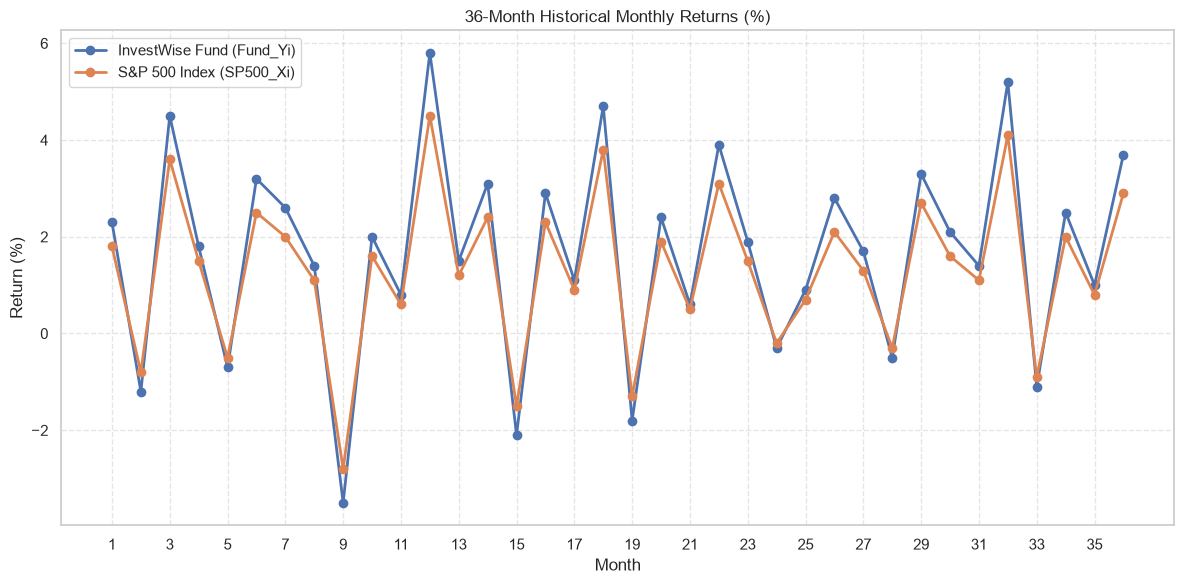

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Fund_Yi'], label='InvestWise Fund (Fund_Yi)', marker='o', linewidth=2)
plt.plot(df.index, df['SP500_Xi'], label='S&P 500 Index (SP500_Xi)', marker='o', linewidth=2)

plt.title('36-Month Historical Monthly Returns (%)')
plt.xlabel('Month')
plt.ylabel('Return (%)')
plt.xticks(df.index[::2])  # show every 2nd month for readability
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

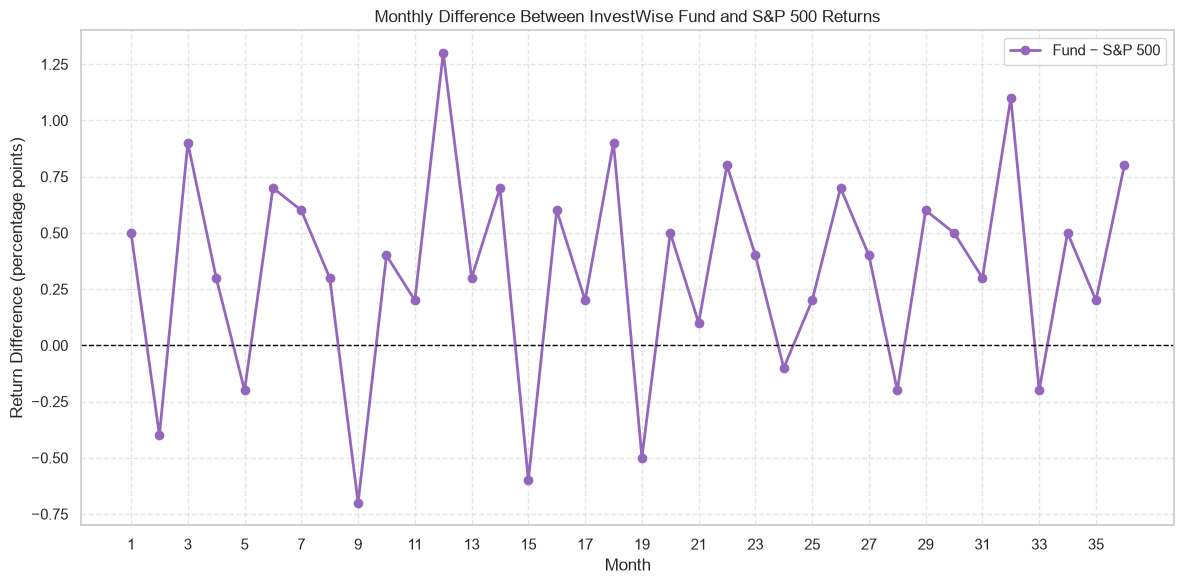

In [50]:
monthly_difference = df["Fund_Yi"] - df["SP500_Xi"]

plt.figure(figsize=(12, 6))
plt.plot(
    df.index,
    monthly_difference,
    marker="o",
    linewidth=2,
    color="tab:purple",
    label="Fund − S&P 500"
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.title("Monthly Difference Between InvestWise Fund and S&P 500 Returns")
plt.xlabel("Month")
plt.ylabel("Return Difference (percentage points)")
plt.xticks(df.index[::2])
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

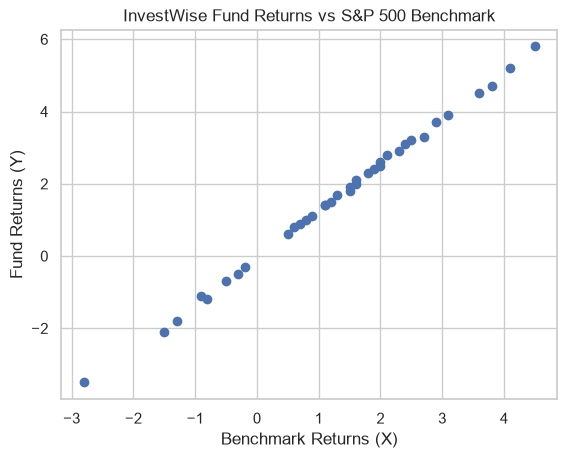

In [46]:
plt.title("InvestWise Fund Returns vs S&P 500 Benchmark")
plt.xlabel("Benchmark Returns (X)")
plt.ylabel("Fund Returns (Y)")
plt.scatter(X,Y)

Regression equation: Y = -0.0385 + 1.2821 * X
Intercept (a): -0.0385
Slope (b): 1.2821
R-squared: 0.9988
RMSE: 0.0719
Correlation (X, Y): 0.9994


,Parameter,Estimate,Metric
0,Intercept,-0.038487,
1,Slope,1.282124,


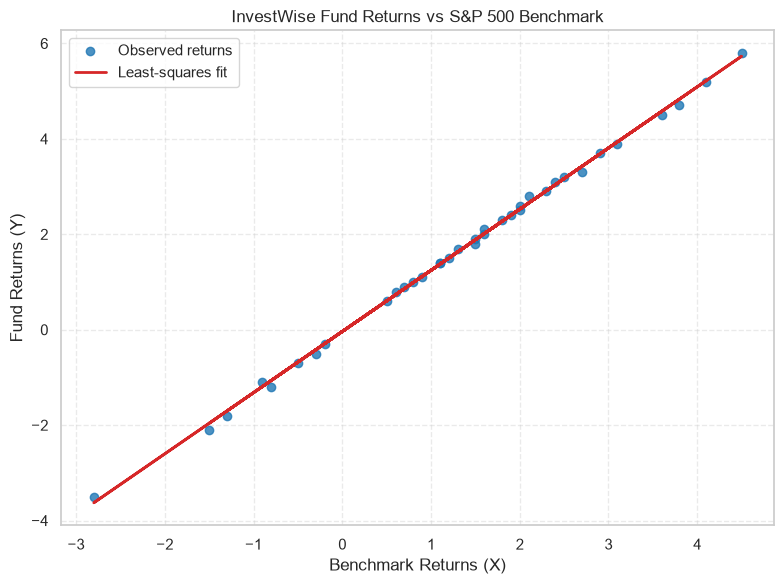

In [44]:
# Linear least-squares model: Fund returns (Y) vs benchmark returns (X)

X = df["SP500_Xi"].to_numpy()
Y = df["Fund_Yi"].to_numpy()

# Design matrix for Y = a + bX
A = np.column_stack([np.ones(len(X)), X])

# Least-squares solution
coef, *_ = np.linalg.lstsq(A, Y, rcond=None)
intercept, slope = coef

y_hat = intercept + slope * X
residuals = Y - y_hat

# Model evaluation metrics
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((Y - Y.mean()) ** 2)
r_squared = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan
rmse = np.sqrt(np.mean(residuals ** 2))
pearson_r = np.corrcoef(X, Y)[0, 1]

print(f"Regression equation: Y = {intercept:.4f} + {slope:.4f} * X")
print(f"Intercept (a): {intercept:.4f}")
print(f"Slope (b): {slope:.4f}")
print(f"R-squared: {r_squared:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"Correlation (X, Y): {pearson_r:.4f}")

results = pd.DataFrame({
    "Parameter": ["Intercept", "Slope"],
    "Estimate": [intercept, slope],
    "Metric": ["", ""]
})

display(results)

plt.figure(figsize=(8, 6))
plt.scatter(X, Y, alpha=0.8, color="tab:blue", label="Observed returns")
plt.plot(X, y_hat, color="tab:red", linewidth=2, label="Least-squares fit")
plt.title("InvestWise Fund Returns vs S&P 500 Benchmark")
plt.xlabel("Benchmark Returns (X)")
plt.ylabel("Fund Returns (Y)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

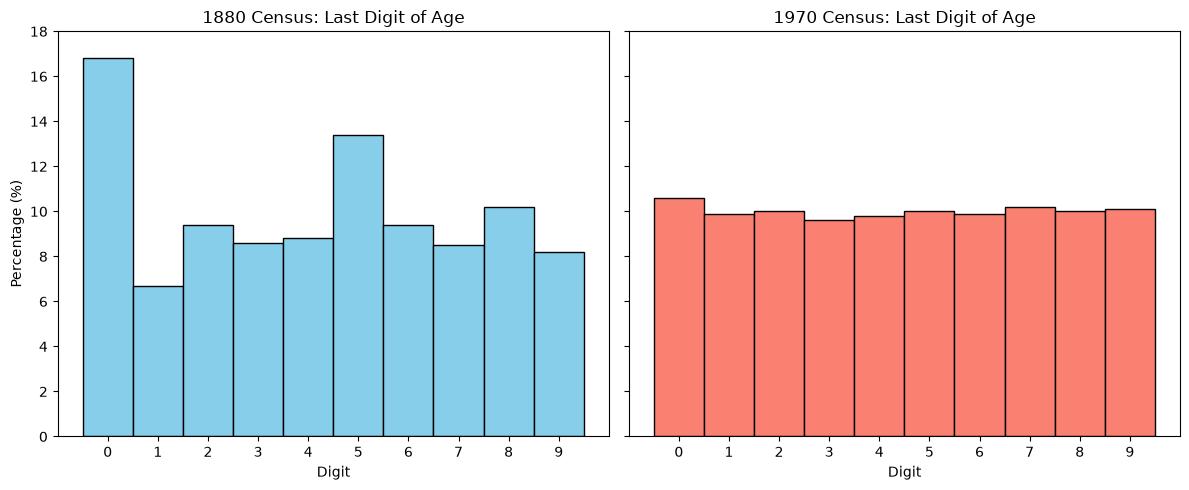

In [8]:
import matplotlib.pyplot as plt

digits = list(range(10))
pct_1880 = [16.8, 6.7, 9.4, 8.6, 8.8, 13.4, 9.4, 8.5, 10.2, 8.2]
pct_1970 = [10.6, 9.9, 10.0, 9.6, 9.8, 10.0, 9.9, 10.2, 10.0, 10.1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# 1880 Plot
ax1.bar(digits, pct_1880, width=1.0, edgecolor='black', color='skyblue', align='center')
ax1.set_title('1880 Census: Last Digit of Age')
ax1.set_xlabel('Digit')
ax1.set_ylabel('Percentage (%)')
ax1.set_xticks(digits)
ax1.set_ylim(0, 18)

# 1970 Plot
ax2.bar(digits, pct_1970, width=1.0, edgecolor='black', color='salmon', align='center')
ax2.set_title('1970 Census: Last Digit of Age')
ax2.set_xlabel('Digit')
ax2.set_xticks(digits)

plt.tight_layout()
plt.show()


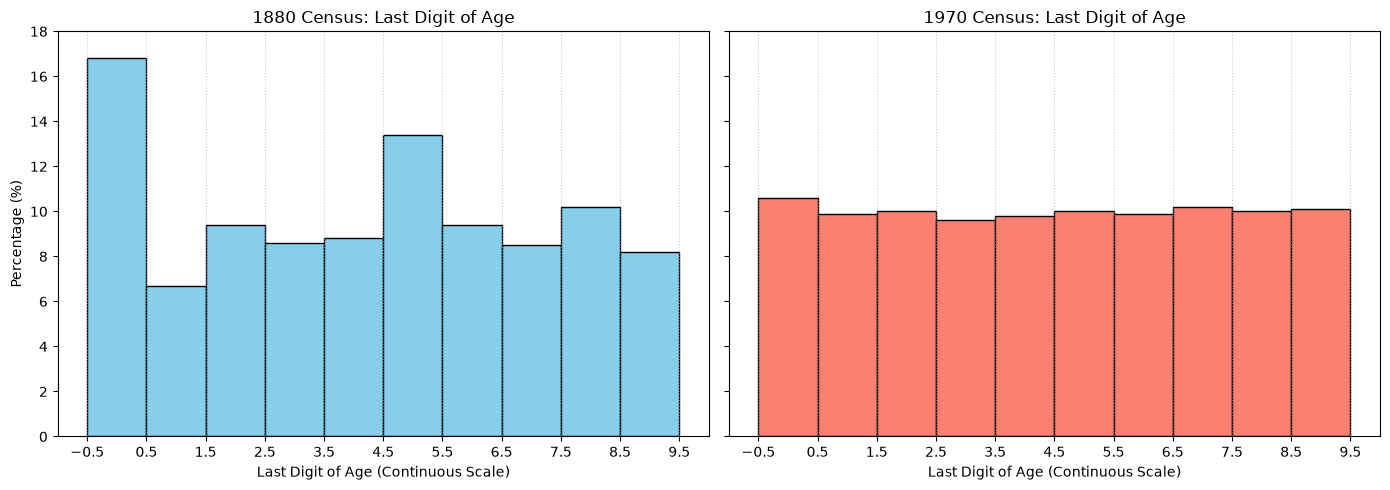

In [9]:
import matplotlib.pyplot as plt

# 1. Define the actual class interval boundaries (endpoints)
# This creates bins: [-0.5, 0.5), [0.5, 1.5), ..., [8.5, 9.5]
bin_edges = [i - 0.5 for i in range(11)]

# Midpoints of the bins (0, 1, 2, ..., 9) to map data correctly
bin_midpoints = list(range(10))

# 2. Extract percentage data from the census table
pct_1880 = [16.8, 6.7, 9.4, 8.6, 8.8, 13.4, 9.4, 8.5, 10.2, 8.2]
pct_1970 = [10.6, 9.9, 10.0, 9.6, 9.8, 10.0, 9.9, 10.2, 10.0, 10.1]

# 3. Create a side-by-side subplot layout sharing the same y-axis scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 4. Generate the 1880 Census histogram
# plt.bar with explicit coordinates maps perfectly to continuous bin intervals
ax1.bar(bin_midpoints, pct_1880, width=1.0, edgecolor='black', color='skyblue')
ax1.set_title('1880 Census: Last Digit of Age')
ax1.set_xlabel('Last Digit of Age (Continuous Scale)')
ax1.set_ylabel('Percentage (%)')
ax1.set_xticks(bin_edges)  # Set ticks exactly at the boundary lines (-0.5, 0.5, etc.)
ax1.set_ylim(0, 18)
ax1.grid(axis='x', linestyle=':', alpha=0.6)

# 5. Generate the 1970 Census histogram
ax2.bar(bin_midpoints, pct_1970, width=1.0, edgecolor='black', color='salmon')
ax2.set_title('1970 Census: Last Digit of Age')
ax2.set_xlabel('Last Digit of Age (Continuous Scale)')
ax2.set_xticks(bin_edges)  # Match the exact boundary lines
ax2.grid(axis='x', linestyle=':', alpha=0.6)

# Adjust layout padding and display the plots
plt.tight_layout()
plt.show()


### inference assignment

In [8]:
import pandas as pd

data = {
    "Geographic Region": [
        "Metro Kolkata (R1)",
        "Urban Non-Metro Districts (R2)",
        "Sub-urban / Semi-Urban (R3)",
        "Interstate Catchment (R4)",
        "Total"
    ],
    "Digital Ads":[187, 114, 63, 102, 466],
    "School Roadshows":[64, 92, 128, 29, 313],
    "Legacy Coaching":[83, 73, 67, 51, 274],
    "Referrals":[78, 49, 43, 24, 194],
    "Total": [412, 328, 301, 206, 1247]
}
df = pd.DataFrame(data)
df

#transpose this data
df_transposed = df.set_index("Geographic Region").transpose().reset_index() 



In [9]:
df_transposed.rename(columns={"index": "Marketing Channel"}, inplace=True)

In [10]:
df_transposed

Geographic Region,Marketing Channel,Metro Kolkata (R1),Urban Non-Metro Districts (R2),Sub-urban / Semi-Urban (R3),Interstate Catchment (R4),Total
0,Digital Ads,187,114,63,102,466
1,School Roadshows,64,92,128,29,313
2,Legacy Coaching,83,73,67,51,274
3,Referrals,78,49,43,24,194
4,Total,412,328,301,206,1247


In [11]:
# Pie chart of total acquisitions by marketing channel

channel_totals = df_transposed[
    df_transposed["Marketing Channel"] != "Total"
].set_index("Marketing Channel")["Total"]

plt.figure(figsize=(8, 8))

plt.pie(
    channel_totals,
    labels=channel_totals.index,
    autopct=lambda pct: f"{pct:.1f}%\n({round(pct * channel_totals.sum() / 100):,})",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.title("Distribution of Total Acquisitions by Marketing Channel")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [12]:
# Calculate Variation Ratio (VR) and IQV for each marketing channel
# across the four geographic regions

regions = [
    "Metro Kolkata (R1)",
    "Urban Non-Metro Districts (R2)",
    "Sub-urban / Semi-Urban (R3)",
    "Interstate Catchment (R4)"
]

channel_region_counts = df_transposed[
    df_transposed["Marketing Channel"] != "Total"
].set_index("Marketing Channel")[regions]

def calculate_vr_iqv(counts):
    proportions = counts / counts.sum()
    k = len(counts)

    return pd.Series({
        "Modal Region": counts.idxmax(),
        "Variation Ratio (VR)": 1 - proportions.max(),
        "IQV": (k / (k - 1)) * (1 - (proportions ** 2).sum())
    })

iqv_vr_table = (
    channel_region_counts
    .apply(calculate_vr_iqv, axis=1)
    .reset_index()
    .rename(columns={"Marketing Channel": "Marketing Channel"})
)

iqv_vr_table[["Variation Ratio (VR)", "IQV"]] = (
    iqv_vr_table[["Variation Ratio (VR)", "IQV"]].round(4)
)

display(iqv_vr_table)

,Marketing Channel,Modal Region,Variation Ratio (VR),IQV
0,Digital Ads,Metro Kolkata (R1),0.5987,0.9506
1,School Roadshows,Sub-urban / Semi-Urban (R3),0.5911,0.9280
2,Legacy Coaching,Metro Kolkata (R1),0.6971,0.9904
3,Referrals,Metro Kolkata (R1),0.5979,0.9468


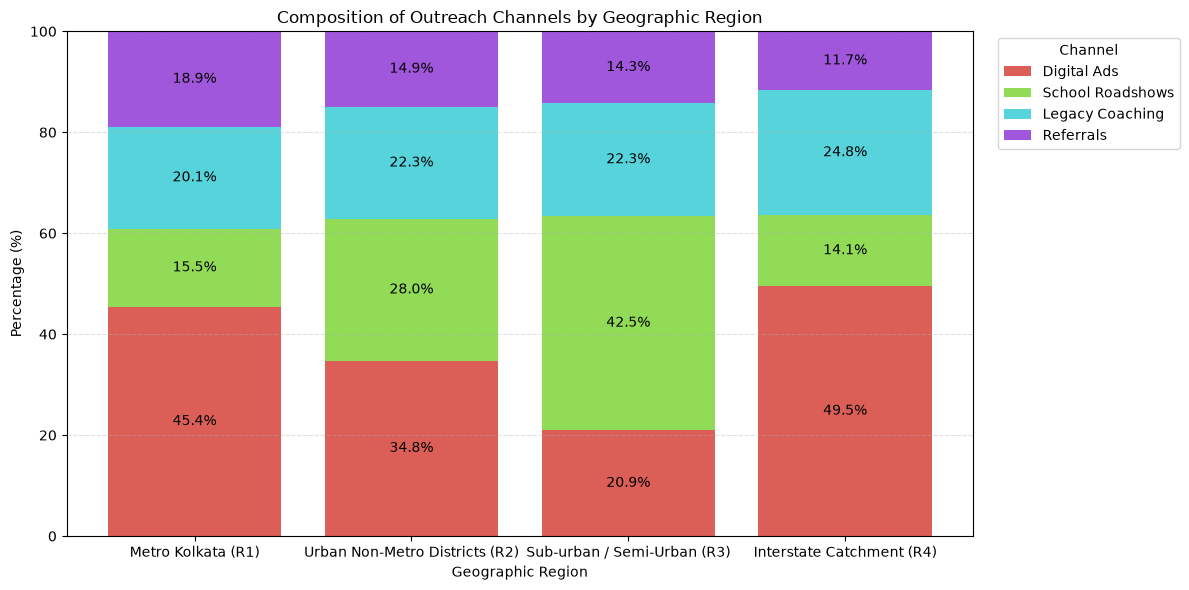

In [13]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
# Exclude the overall Total row
region_df = df[df["Geographic Region"] != "Total"].copy()

channels = ["Digital Ads", "School Roadshows", "Legacy Coaching", "Referrals"]

# Convert counts to row-wise percentages
percentage_df = region_df.set_index("Geographic Region")[channels].div(
    region_df.set_index("Geographic Region")[channels].sum(axis=1),
    axis=0
) * 100

# Use a distinct, colorblind-friendly palette
colors = sns.color_palette("hls", n_colors=len(channels))


fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(percentage_df))

for channel, color in zip(channels, colors):
    values = percentage_df[channel].to_numpy()
    ax.bar(
        percentage_df.index,
        values,
        bottom=bottom,
        label=channel,
        color=color
    )
    bottom += values

for container in ax.containers:
    labels = [f"{value:.1f}%" for value in container.datavalues]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="black",
        fontsize=10
    )
ax.set_title("Composition of Outreach Channels by Geographic Region")
ax.set_xlabel("Geographic Region")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)

ax.legend(title="Channel", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=0, ha="center")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


NameError: name 'TOTAL_POOL_SIZE' is not defined

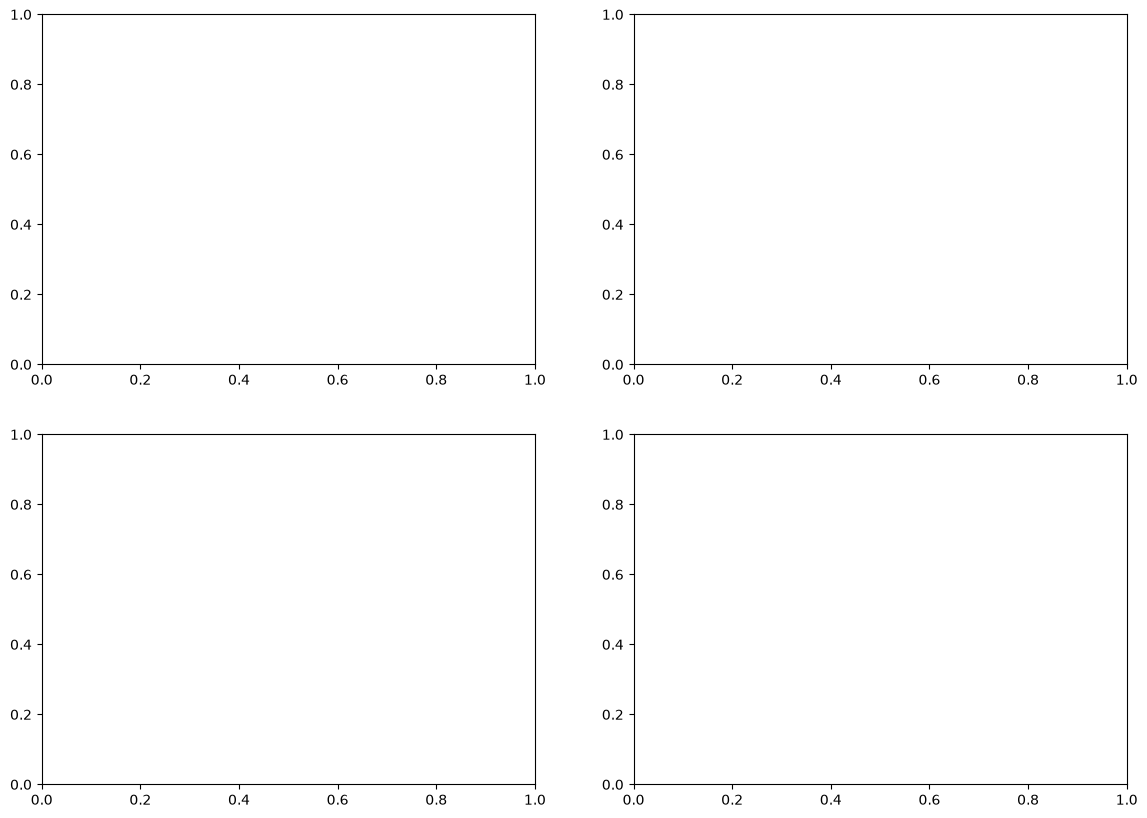

In [14]:
# Four pie charts showing each marketing channel's distribution across regions

regions = region_df["Geographic Region"].tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, channel, color in zip(axes, channels, colors):
    values = region_df[channel].to_numpy()
    total_count = values.sum()
    total_proportion = total_count / TOTAL_POOL_SIZE * 100

    palette = sns.light_palette(
        color,
        n_colors=len(regions) + 1
    )[1:][::-1]

    ax.pie(
        values,
        labels=regions,
        autopct=lambda pct, vals=values: (
            f"{pct:.1f}%\n({round(pct * vals.sum() / 100):,})"
        ),
        startangle=90,
        colors=palette,
        wedgeprops={"edgecolor": "white", "linewidth": 1}
    )

    ax.set_title(f"{channel}\nComposition by Region")
    ax.text(
        0.5, -0.10,
        f"Total count: {total_count:,} | "
        f"Total proportion: {total_proportion:.1f}%",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "Regional Composition of Marketing Channels",
    fontsize=16,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.06, right=0.94,
    bottom=0.10, top=0.88,
    wspace=0.30, hspace=0.35
)

fig.add_artist(plt.Line2D(
    [0.5, 0.5], [0.08, 0.88],
    transform=fig.transFigure,
    color="gray",
    linewidth=1.2
))

fig.add_artist(plt.Line2D(
    [0.06, 0.94], [0.48, 0.48],
    transform=fig.transFigure,
    color="gray",
    linewidth=1.2
))

plt.show()

In [ ]:
# Variation Ratio and Index of Qualitative Variation by geographical region

def qualitative_dispersion(counts):
    counts = counts.astype(float)
    total = counts.sum()
    proportions = counts / total
    k = len(counts)

    variation_ratio = 1 - proportions.max()
    iqv = (k / (k - 1)) * (1 - np.sum(proportions ** 2))

    return pd.Series({
        "Modal Channel": counts.idxmax(),
        "Variation Ratio": variation_ratio,
        "IQV": iqv
    })

dispersion_table = (
    region_df.set_index("Geographic Region")[channels]
    .apply(qualitative_dispersion, axis=1)
    .reset_index()
)

dispersion_table[["Variation Ratio", "IQV"]] = dispersion_table[
    ["Variation Ratio", "IQV"]
].round(4)

dispersion_table

,Geographic Region,Modal Channel,Variation Ratio,IQV
0,Metro Kolkata (R1),Digital Ads,0.5461,0.9246
1,Urban Non-Metro Districts (R2),Digital Ads,0.6524,0.9716
2,Sub-urban / Semi-Urban (R3),School Roadshows,0.5748,0.9405
3,Interstate Catchment (R4),Digital Ads,0.5049,0.8802


In [ ]:
# Calculate expected frequencies for the region-by-channel contingency table

observed = df.loc[df["Geographic Region"] != "Total", channels].copy()

expected_values = (
    observed.sum(axis=1).to_numpy()[:, None]
    * observed.sum(axis=0).to_numpy()[None, :]
    / observed.to_numpy().sum()
)

expected_df = pd.DataFrame(
    expected_values,
    index=observed.index,
    columns=channels
)

expected_df.index = df.loc[df["Geographic Region"] != "Total", "Geographic Region"]
expected_df.index.name = "Geographic Region"

display(expected_df.round(2))

,Digital Ads,School Roadshows,Legacy Coaching,Referrals
Geographic Region,,,,
Metro Kolkata (R1),153.96,103.41,90.53,64.10
Urban Non-Metro Districts (R2),122.57,82.33,72.07,51.03
Sub-urban / Semi-Urban (R3),112.48,75.55,66.14,46.83
Interstate Catchment (R4),76.98,51.71,45.26,32.05


In [15]:
from scipy.stats import chi2

# Pearson chi-square statistic
chi_square = ((observed.to_numpy() - expected_df.to_numpy()) ** 2 / expected_df.to_numpy()).sum()

degrees_of_freedom = (observed.shape[0] - 1) * (observed.shape[1] - 1)
p_value = chi2.sf(chi_square, degrees_of_freedom)

print(f"Chi-square statistic: {chi_square:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6f}")
print(
    f"The observed frequencies are {chi_square:.4f} chi-square units "
    "away from the frequencies expected under independence."
)

NameError: name 'observed' is not defined

In [23]:
import pandas as pd

# 1. Recreate the data from the updated Exhibit 2 image
data = {
    "Acquisition Channel": [
        "Digital Ads",
        "School Roadshows",
        "Legacy Coaching",
        "Referrals"
    ],
    "Accepted & Enrolled": [167, 136, 113, 103],
    "Offer Declined / Forfeited": [148, 71, 53, 43],
    "Total": [315, 207, 166, 146]
}

# Create DataFrame
df_init = pd.DataFrame(data)
df = pd.DataFrame(data)
# 2. Calculate the channel-wise probability of acceptance
df["Channel-wise Probability"] = df["Accepted & Enrolled"] / df["Total"]

# 3. Calculate the overall probability of acceptance
overall_accepted = df["Accepted & Enrolled"].sum()
overall_total = df["Total"].sum()
overall_probability = overall_accepted / overall_total

# 4. Generate the structured comparison summary table
summary_df = df[["Acquisition Channel", "Channel-wise Probability"]].copy()

# Add a summary row for the Overall Baseline metric
overall_row = pd.DataFrame([{
    "Acquisition Channel": "Overall Baseline",
    "Channel-wise Probability": overall_probability
}])

summary_df = pd.concat([summary_df, overall_row], ignore_index=True)

# Format the probability values as clean strings with percentages
summary_df["Channel-wise Probability"] = summary_df["Channel-wise Probability"].map(lambda x: f"{x*100:.2f}%")

summary_df


,Acquisition Channel,Channel-wise Probability
0,Digital Ads,53.02%
1,School Roadshows,65.70%
2,Legacy Coaching,68.07%
3,Referrals,70.55%
4,Overall Baseline,62.23%


In [24]:
df_init

,Acquisition Channel,Accepted & Enrolled,Offer Declined / Forfeited,Total
0,Digital Ads,167,148,315
1,School Roadshows,136,71,207
2,Legacy Coaching,113,53,166
3,Referrals,103,43,146


In [17]:
colors

[(0.86, 0.3712, 0.33999999999999997),
 (0.5688000000000001, 0.86, 0.33999999999999997),
 (0.33999999999999997, 0.8287999999999999, 0.86),
 (0.6311999999999998, 0.33999999999999997, 0.86)]

In [18]:
df_init

,Acquisition Channel,Accepted & Enrolled,Offer Declined / Forfeited,Total
0,Digital Ads,167,148,315
1,School Roadshows,136,71,207
2,Legacy Coaching,113,53,166
3,Referrals,103,43,146


In [19]:
colors = ["#1D2F6F", "#FAC748"]
# In Matplotlib loop: ax.bar(..., color=colors[i])
# In Pandas: df.plot.bar(stacked=True, ax=ax, color=colors)
colors

['#1D2F6F', '#FAC748']

In [21]:
percentage_df

,Digital Ads,School Roadshows,Legacy Coaching,Referrals
Geographic Region,,,,
Metro Kolkata (R1),45.388350,15.533981,20.145631,18.932039
Urban Non-Metro Districts (R2),34.756098,28.048780,22.256098,14.939024
Sub-urban / Semi-Urban (R3),20.930233,42.524917,22.259136,14.285714
Interstate Catchment (R4),49.514563,14.077670,24.757282,11.650485


In [25]:
# Create row-wise percentage data from df_init
outcome_columns = [
    "Accepted & Enrolled",
    "Offer Declined / Forfeited"
]

percentage_df = df_init.set_index("Acquisition Channel")[outcome_columns].div(
    df_init.set_index("Acquisition Channel")["Total"],
    axis=0
).mul(100)

# Add the overall baseline
percentage_df.loc["Overall"] = (
    df_init[outcome_columns].sum()
    / df_init["Total"].sum()
    * 100
)

display(percentage_df.round(2))

,Accepted & Enrolled,Offer Declined / Forfeited
Acquisition Channel,,
Digital Ads,53.02,46.98
School Roadshows,65.70,34.30
Legacy Coaching,68.07,31.93
Referrals,70.55,29.45
Overall,62.23,37.77


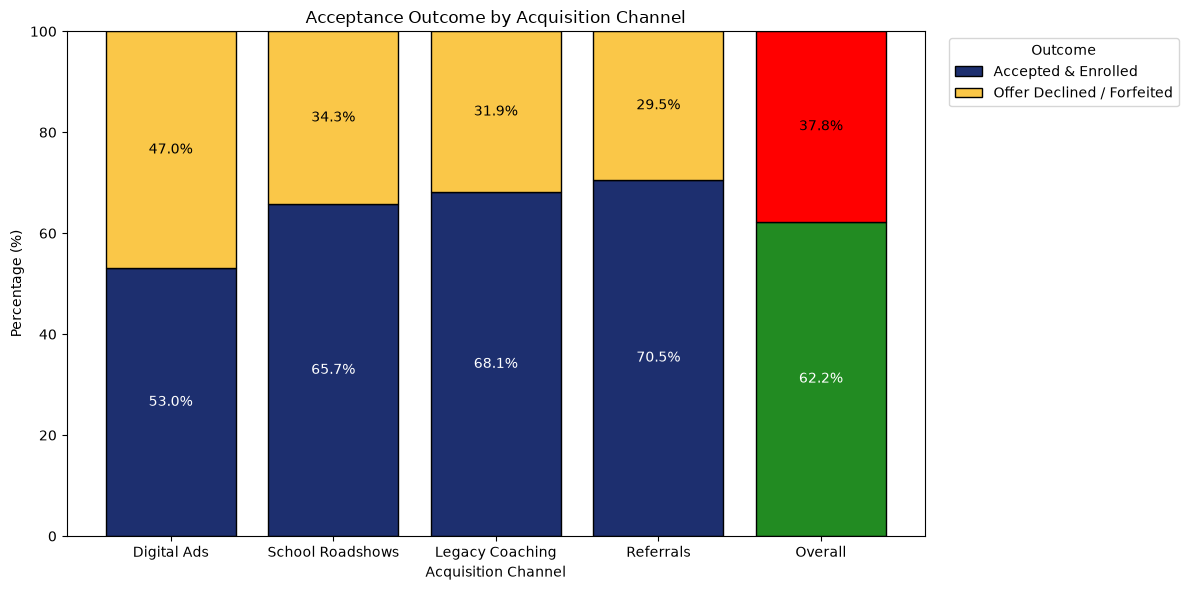

In [27]:
# 100% stacked bar chart with a distinct Overall bar
import numpy as np
x = np.arange(len(percentage_df.index))
accepted = percentage_df["Accepted & Enrolled"].to_numpy()
declined = percentage_df["Offer Declined / Forfeited"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 6))

# Regular channel bars
ax.bar(
    x[:-1],
    accepted[:-1],
    color=colors[0],
    edgecolor="black",
    label="Accepted & Enrolled"
)
ax.bar(
    x[:-1],
    declined[:-1],
    bottom=accepted[:-1],
    color=colors[1],
    edgecolor="black",
    label="Offer Declined / Forfeited"
)

# Distinct Overall bar with a softer red
ax.bar(
    x[-1],
    accepted[-1],
    color="forestgreen",
    edgecolor="black"
)
ax.bar(
    x[-1],
    declined[-1],
    bottom=accepted[-1],
    color="red",
    edgecolor="black"
)


ax.set_title("Acceptance Outcome by Acquisition Channel")
ax.set_xlabel("Acquisition Channel")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.set_xticks(x)
ax.set_xticklabels(percentage_df.index)
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
# ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.grid(False)
# Add percentage labels
for i in range(len(percentage_df)):
    if accepted[i] >= 3:
        ax.text(i, accepted[i] / 2, f"{accepted[i]:.1f}%",
                ha="center", va="center", color="white")
    if declined[i] >= 3:
        ax.text(i, accepted[i] + declined[i] / 2, f"{declined[i]:.1f}%",
                ha="center", va="center", color="black")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


C:\Users\Nishad\AppData\Local\Temp\ipykernel_25132\3245830586.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


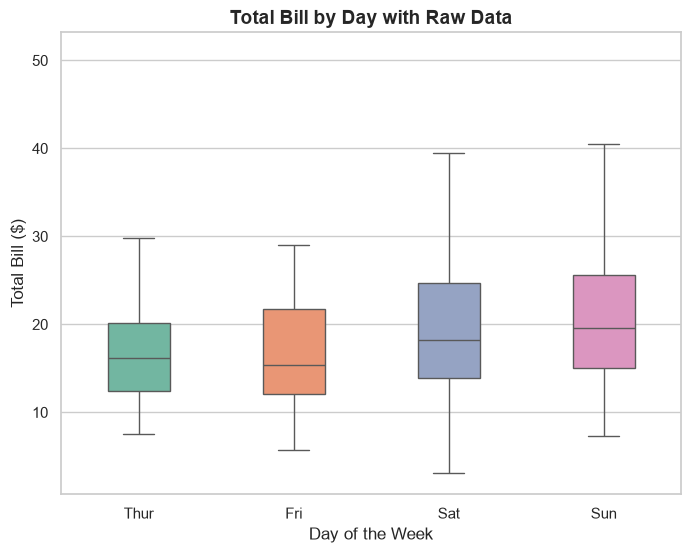

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean aesthetic theme
sns.set_theme(style="whitegrid")

# Load sample data
df = sns.load_dataset("tips")

# Create figure
plt.figure(figsize=(8, 6))

# Draw the box plot
sns.boxplot(
    x="day",
    y="total_bill",
    data=df,
    palette="Set2",
    width=0.4,
    fliersize=0,  # Hide default outliers if overlaying points
)

# Overlay individual data points for a richer view
# sns.stripplot(
#     x="day", y="total_bill", data=df, color="black", alpha=0.5, jitter=0.2, size=5
# )

# Add titles and labels
plt.title("Total Bill by Day with Raw Data", fontsize=14, fontweight="bold")
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total Bill ($)", fontsize=12)

plt.show()


In [17]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean styling for academic/executive reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "axes.labelsize": 12, "axes.titlesize": 14})

# ==========================================
# 1. DATA PREPARATION & MAPPING
# ==========================================

# Total pool size across top-of-funnel acquisitions
TOTAL_POOL_SIZE = 1247

# Top-of-funnel acquisition raw counts
total_acquisitions = {
    "Digital Performance Ads": 466,
    "Regional School Roadshows": 313,
    "Legacy Coaching Tie-ups": 274,
    "Alumni / Student Referrals": 194,
}

# Dataset 2: Bottom-of-Funnel Conversion Data (from the 834 pool)
conversion_data = {
    "Acquisition Channel": [
        "Digital Performance Ads",
        "Regional School Roadshows",
        "Legacy Coaching Tie-ups",
        "Alumni / Student Referrals",
    ],
    "Accepted & Enrolled":[167,136,113,103],
    "Offer Declined / Forfeited":[148,71,53,43],
    "Total_Shortlisted":[315,207,166,146],
}

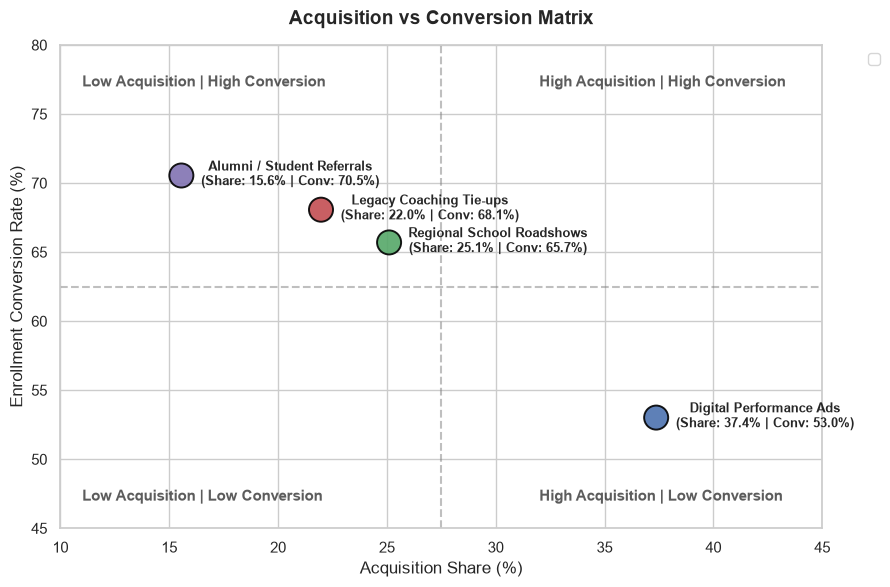

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Clean styling for reports
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "axes.labelsize": 12, "axes.titlesize": 14})

# ==========================================
# 1. DATA PREPARATION
# ==========================================
TOTAL_POOL_SIZE = 1247


df = pd.DataFrame(conversion_data)
df["Acquisition_Share_Pct"] = (
    df["Acquisition Channel"].map(total_acquisitions) / TOTAL_POOL_SIZE
) * 100
df["Conversion_Rate_Pct"] = (
    df["Accepted & Enrolled"] / df["Total_Shortlisted"]
) * 100

# ==========================================
# 2. EFFICIENCY SHARE MATRIX
# ==========================================
plt.figure(figsize=(9, 6))
colors = ["#4c72b0", "#55a868", "#c44e52", "#8172b2"]

# Scatter plot
sns.scatterplot(
    data=df,
    x="Acquisition_Share_Pct",
    y="Conversion_Rate_Pct",
    hue="Acquisition Channel",
    palette=colors,
    s=300,
    alpha=0.9,
    edgecolor="black",
)

# Reference quadrant lines (using center-scaled values for clean visual framing)
x_center = 27.5
y_center = 62.5

plt.axvline(x=x_center, color="gray", linestyle="--", alpha=0.5)
plt.axhline(y=y_center, color="gray", linestyle="--", alpha=0.5)

# Label data points
for i in range(len(df)):
    plt.text(
        df["Acquisition_Share_Pct"][i]+5,
        df["Conversion_Rate_Pct"][i] -0.7,
        f"{df['Acquisition Channel'][i]}\n(Share: {df['Acquisition_Share_Pct'][i]:.1f}% | Conv: {df['Conversion_Rate_Pct'][i]:.1f}%)",
        horizontalalignment="center",
        size="small",
        weight="semibold",
    )

# Strict Quadrant Metric Labels
plt.text(
    11,
    77,
    "Low Acquisition | High Conversion",
    color="#333333",
    weight="bold",
    alpha=0.8,
)
plt.text(
    32,
    77,
    "High Acquisition | High Conversion",
    color="#333333",
    weight="bold",
    alpha=0.8,
)
plt.text(
    11,
    47,
    "Low Acquisition | Low Conversion",
    color="#333333",
    weight="bold",
    alpha=0.8,
)
plt.text(
    32,
    47,
    "High Acquisition | Low Conversion",
    color="#333333",
    weight="bold",
    alpha=0.8,
)

# Chart Formatting
plt.title("Acquisition vs Conversion Matrix", pad=15, fontweight="bold")
plt.xlabel("Acquisition Share (%)")
plt.ylabel("Enrollment Conversion Rate (%)")
plt.xlim(10, 45)
plt.ylim(45, 80)
plt.legend([], bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Save final graphic
plt.savefig("efficiency_matrix_percentage.png", dpi=300)
plt.show()


In [9]:
# Expected frequencies for the acquisition channel contingency table

observed = df_init[
    ["Accepted & Enrolled", "Offer Declined / Forfeited"]
]

expected_values = (
    observed.sum(axis=1).to_numpy()[:, None]
    * observed.sum(axis=0).to_numpy()[None, :]
    / observed.to_numpy().sum()
)

expected_df = pd.DataFrame(
    expected_values,
    index=df_init["Acquisition Channel"],
    columns=observed.columns
)

expected_df.index.name = "Acquisition Channel"

display(expected_df.round(2))

,Accepted & Enrolled,Offer Declined / Forfeited
Acquisition Channel,,
Digital Performance Ads,196.03,118.97
Regional School Roadshows,128.82,78.18
Legacy Coaching Tie-ups,103.30,62.70
Alumni / Student Referrals,90.86,55.14


In [12]:
# Chi-square test and Cramer's V using df_init and expected_df
from scipy.stats import chi2
import numpy as np
observed = df_init[
    ["Accepted & Enrolled", "Offer Declined / Forfeited"]
].to_numpy()

expected = expected_df.to_numpy()

chi_square = ((observed - expected) ** 2 / expected).sum()

rows, columns = observed.shape
degrees_of_freedom = (rows - 1) * (columns - 1)
p_value = chi2.sf(chi_square, degrees_of_freedom)

n = observed.sum()
cramers_v = np.sqrt(
    chi_square / (n * min(rows - 1, columns - 1))
)

print(f"Chi-square statistic: {chi_square:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.4f}")

Chi-square statistic: 19.1473
Degrees of freedom: 3
P-value: 0.000255
Cramer's V: 0.1515


In [26]:
import pandas as pd

# Define the table data from Exhibit 3
data = {
    "Acquisition Channel": [
        "Digital Performance Ads",
        "Regional School Roadshows",
        "Total"
    ],
    "1 (Very Poor)":[47,16,63],
    "2 (Poor)": [78, 31, 109],
    "3 (Moderate)": [96, 79, 175],
    "4 (High)": [64, 124, 188],
    "5 (Very High)": [29, 63, 92],
    "Total": [314, 313, 627]
}

# Create the DataFrame
df = pd.DataFrame(data)
df



,Acquisition Channel,1 (Very Poor),2 (Poor),3 (Moderate),4 (High),5 (Very High),Total
0,Digital Performance Ads,47,78,96,64,29,314
1,Regional School Roadshows,16,31,79,124,63,313
2,Total,63,109,175,188,92,627


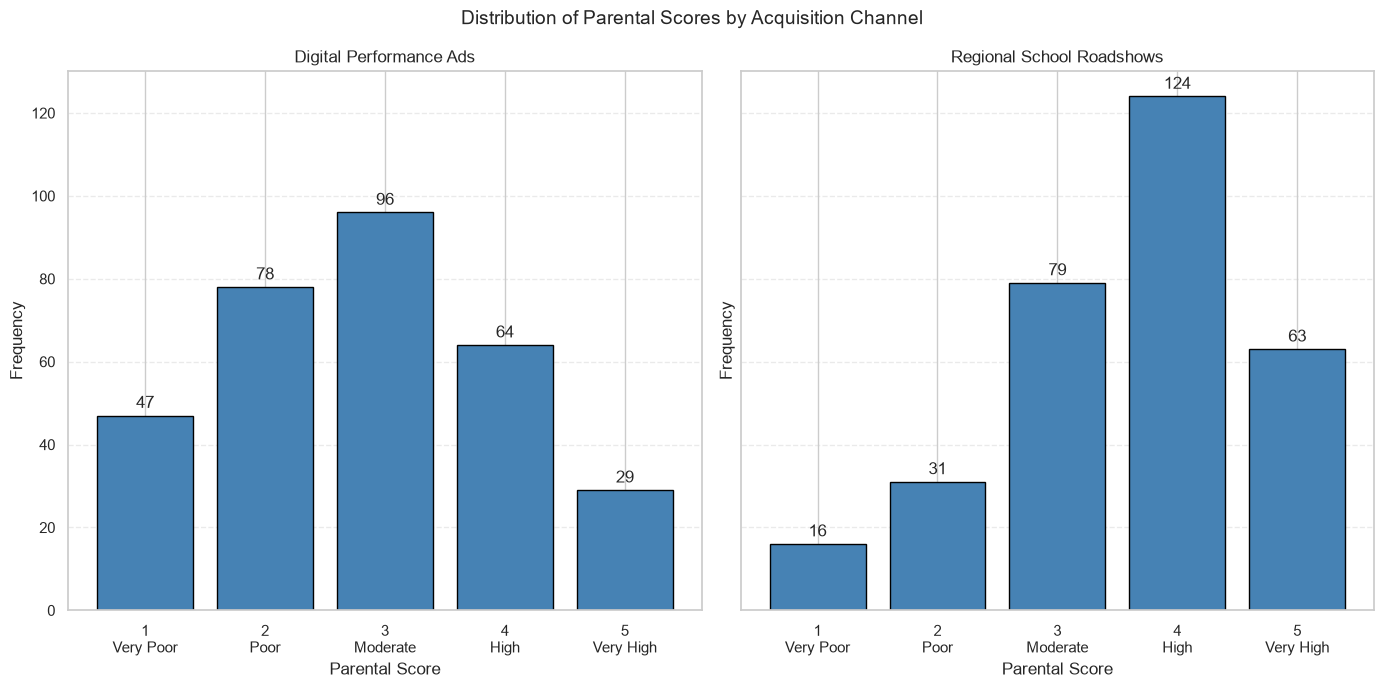

In [27]:
# Plot score distributions for the two acquisition channels
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

score_columns = [
    "1 (Very Poor)",
    "2 (Poor)",
    "3 (Moderate)",
    "4 (High)",
    "5 (Very High)"
]

channel_df = df[df["Acquisition Channel"] != "Total"]

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

for ax, (_, row) in zip(axes, channel_df.iterrows()):
    counts = row[score_columns].to_numpy()
    scores = np.arange(1, 6)

    bars = ax.bar(scores, counts, color="steelblue", edgecolor="black")
    ax.bar_label(bars, padding=3)

    ax.set_title(row["Acquisition Channel"])
    ax.set_xlabel("Parental Score")
    ax.set_ylabel("Frequency")
    ax.set_xticks(scores)
    ax.set_xticklabels(["1\nVery Poor", "2\nPoor", "3\nModerate", "4\nHigh", "5\nVery High"])
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Distribution of Parental Scores by Acquisition Channel", fontsize=14)
plt.tight_layout()
plt.show()

In [28]:
# Percentage and cumulative percentage by acquisition channel and score

percentage_tables = {}

for _, row in channel_df.iterrows():
    channel = row["Acquisition Channel"]
    counts = row[score_columns].astype(int)
    total = counts.sum()

    table = pd.DataFrame({
        "Score": scores,
        "Response Category": score_columns,
        "Count": counts.values,
        "Percent (%)": (counts.values / total * 100).round(2),
    },index=None)

    table["Cumulative Percent (%)"] = table["Percent (%)"].cumsum().round(2)
    percentage_tables[channel] = table

    print(f"\n                   {channel}")
    display(table)


                   Digital Performance Ads


,Score,Response Category,Count,Percent (%),Cumulative Percent (%)
0,1,1 (Very Poor),47,14.97,14.97
1,2,2 (Poor),78,24.84,39.81
2,3,3 (Moderate),96,30.57,70.38
3,4,4 (High),64,20.38,90.76
4,5,5 (Very High),29,9.24,100.00



                   Regional School Roadshows


,Score,Response Category,Count,Percent (%),Cumulative Percent (%)
0,1,1 (Very Poor),16,5.11,5.11
1,2,2 (Poor),31,9.90,15.01
2,3,3 (Moderate),79,25.24,40.25
3,4,4 (High),124,39.62,79.87
4,5,5 (Very High),63,20.13,100.00


In [32]:
colors

['#1D2F6F', '#FAC748']

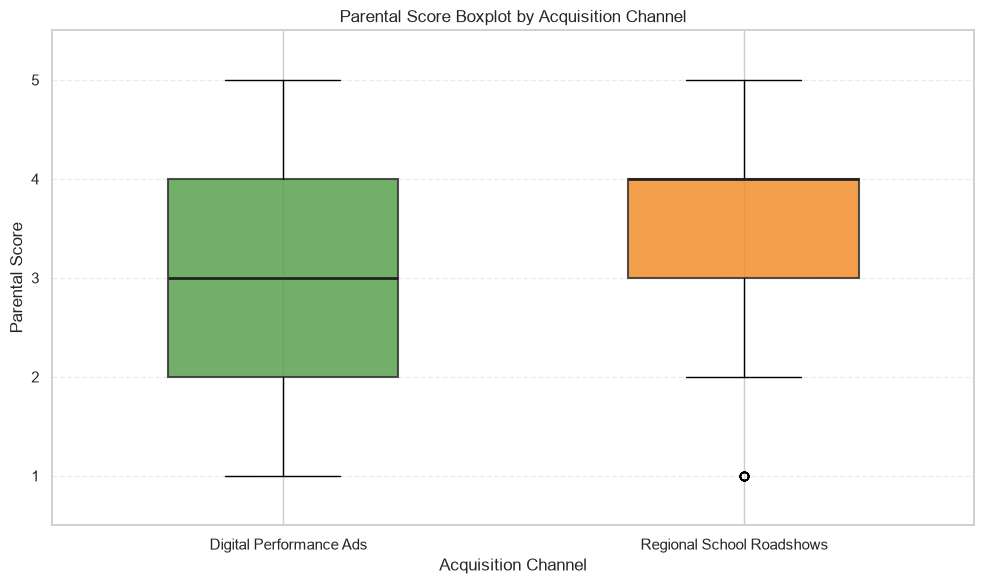

In [68]:
# Create expanded score arrays for each acquisition channel
channel_responses = {
    row["Acquisition Channel"]: np.repeat(
        scores,
        row[score_columns].to_numpy(dtype=int)
    )
    for _, row in channel_df.iterrows()
}

channel_names = list(channel_responses.keys())

fig, ax = plt.subplots(figsize=(10, 6))

boxplot = ax.boxplot(
    list(channel_responses.values()),
    tick_labels=channel_names,  # updated Matplotlib argument
    patch_artist=True,
    widths=0.5
)
# set x label under the box plot
plt.setp(ax.get_xticklabels(), ha="right")

# colors = ["steelblue", "steelblue"]
colors=[ "#59A14F", "#F28E2B"]

for box, color in zip(boxplot["boxes"], colors):
    # box.set_facecolor(color)
    box.set_alpha(0.75)

ax.set_title("Parental Score Boxplot by Acquisition Channel")
ax.set_xlabel("Acquisition Channel")
ax.set_ylabel("Parental Score")
ax.set_ylim(0.5, 5.5)
ax.set_yticks(scores)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=0, ha="right")
# Apply the transform to all x-axis tick labels
import matplotlib.transforms as mtrans

# Create a translation transform (shift x pixels right, 0 pixels down)
shift_pixels = 85
trans = mtrans.Affine2D().translate(shift_pixels, 0)
import matplotlib.transforms as mtrans

for label in ax.get_xticklabels():
  label.set_transform(label.get_transform() + trans)
plt.tight_layout()

colors = ["#2A9D8F", "#E76F51"]  # teal and coral
colors=[ "#59A14F", "#F28E2B"]
for box, color in zip(boxplot["boxes"], colors):
    box.set_facecolor(color)
    box.set_edgecolor("#333333")
    box.set_alpha(0.85)
    box.set_linewidth(1.5)

for median in boxplot["medians"]:
    median.set_color("#222222")
    median.set_linewidth(2)
    
plt.show()


In [15]:
summary_table_transposed = summary_table.set_index(
    "Acquisition Channel"
).transpose()


summary_table_transposed = summary_table_transposed.rename(
    index={"IQR": "Interquartile Interval (Q1–Q3)"}
)

display(summary_table_transposed)

Acquisition Channel,Digital Performance Ads,Regional School Roadshows
Median,3.00,4.00
Interquartile Interval (Q1–Q3),2.00,1.00
Bottom-Two-Box (%),39.81,15.02
Top-Two-Box (%),29.62,59.74


In [20]:
# Leik's index of ordinal dispersion for each acquisition channel

def leiks_index(counts):
    counts = np.asarray(counts, dtype=float)
    cumulative_proportions = np.cumsum(counts) / counts.sum()

    # Use cumulative proportions through categories 1 to K-1
    fk = np.minimum(
        cumulative_proportions[:-1],
        1 - cumulative_proportions[:-1]
    )

    K = len(counts)
    return (2 / (K - 1)) * fk.sum()


leiks_results = pd.DataFrame({
    "Acquisition Channel": channel_df["Acquisition Channel"],
    "Leik's Index (D)": [
        leiks_index(row[score_columns])
        for _, row in channel_df.iterrows()
    ]
})

leiks_results["Leik's Index (D)"] = leiks_results["Leik's Index (D)"].round(4)

# display(leiks_results)

# Blair-Lacy's index of ordinal dispersion for each acquisition channel

def blair_lacy_index(counts):
    counts = np.asarray(counts, dtype=float)
    cumulative_proportions = np.cumsum(counts) / counts.sum()

    K = len(counts)
    l_squared = (
        4 / (K - 1)
        * np.sum((cumulative_proportions[:-1] - 0.5) ** 2)
    )

    return 1 - l_squared


blair_lacy_results = pd.DataFrame({
    "Acquisition Channel": channel_df["Acquisition Channel"],
    "Blair-Lacy's Index (D_bl)": [
        blair_lacy_index(row[score_columns])
        for _, row in channel_df.iterrows()
    ]
})

blair_lacy_results["Blair-Lacy's Index (D_bl)"] = (
    blair_lacy_results["Blair-Lacy's Index (D_bl)"].round(4)
)

# display(blair_lacy_results)
dispersion_results = leiks_results.merge(
    blair_lacy_results,
    on="Acquisition Channel"
)

display(dispersion_results)


,Acquisition Channel,Leik's Index (D),Blair-Lacy's Index (D_bl)
0,Digital Performance Ads,0.4682,0.6592
1,Regional School Roadshows,0.4026,0.5774


In [40]:
import pandas as pd

# Define the table data
data = {
    "Academic Department": ["CS-AI", "ECE", "ME", "CE", "Total"],
    "1 (Ext. Dissat.)":[16, 21, 37, 36, 110],
    "2 (Dissat.)":[36, 42, 46, 16, 140],
    "3 (Neutral)":[72, 83, 41, 11, 207],
    "4 (Satisfied)":[184, 81, 19, 14, 298],
    "5 (Ext. Sat.)":[101, 29, 11, 22, 163],
    "Total": [409, 256, 154, 99, 918]
}

# Create the DataFrame
df = pd.DataFrame(data)

# Set the department column as index (optional)
df.set_index("Academic Department", inplace=True)
df


,1 (Ext. Dissat.),2 (Dissat.),3 (Neutral),4 (Satisfied),5 (Ext. Sat.),Total
Academic Department,,,,,,
CS-AI,16,36,72,184,101,409
ECE,21,42,83,81,29,256
ME,37,46,41,19,11,154
CE,36,16,11,14,22,99
Total,110,140,207,298,163,918


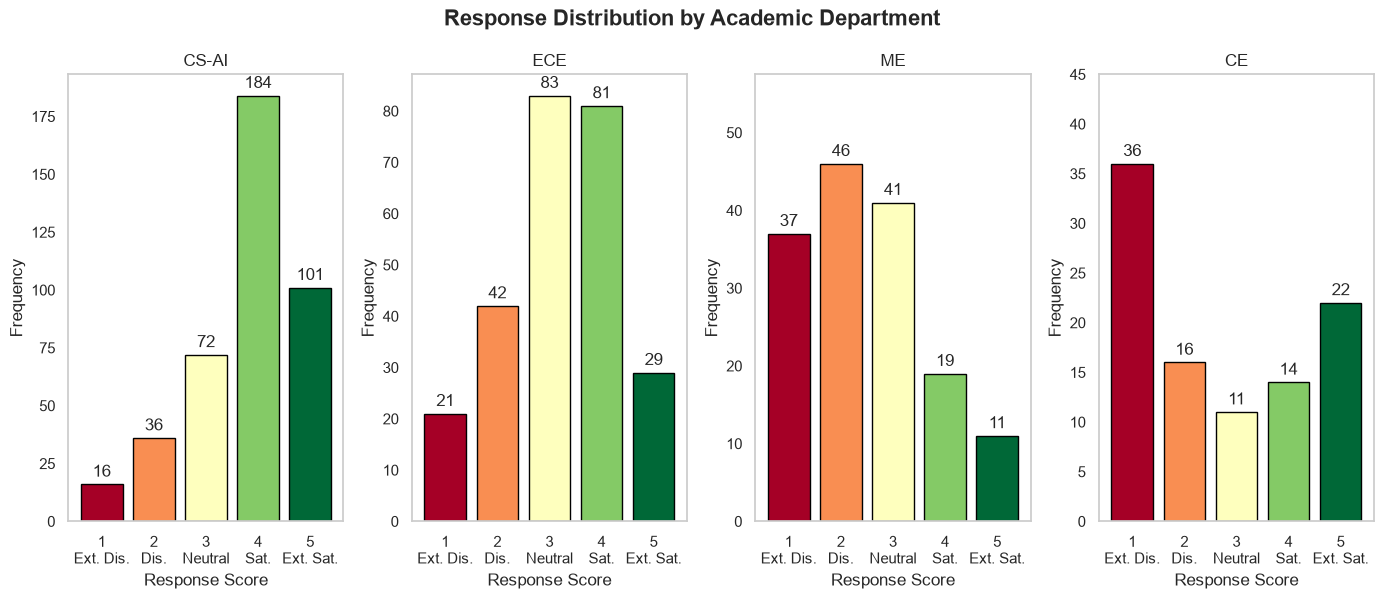


CS-AI


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 (Ext. Dissat.),16,3.91,3.91
1,2 (Dissat.),36,8.80,12.71
2,3 (Neutral),72,17.60,30.32
3,4 (Satisfied),184,44.99,75.31
4,5 (Ext. Sat.),101,24.69,100.00



ECE


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 (Ext. Dissat.),21,8.20,8.20
1,2 (Dissat.),42,16.41,24.61
2,3 (Neutral),83,32.42,57.03
3,4 (Satisfied),81,31.64,88.67
4,5 (Ext. Sat.),29,11.33,100.00



ME


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 (Ext. Dissat.),37,24.03,24.03
1,2 (Dissat.),46,29.87,53.90
2,3 (Neutral),41,26.62,80.52
3,4 (Satisfied),19,12.34,92.86
4,5 (Ext. Sat.),11,7.14,100.00



CE


,Response Category,Count,Percentage (%),Cumulative Percentage (%)
0,1 (Ext. Dissat.),36,36.36,36.36
1,2 (Dissat.),16,16.16,52.53
2,3 (Neutral),11,11.11,63.64
3,4 (Satisfied),14,14.14,77.78
4,5 (Ext. Sat.),22,22.22,100.00


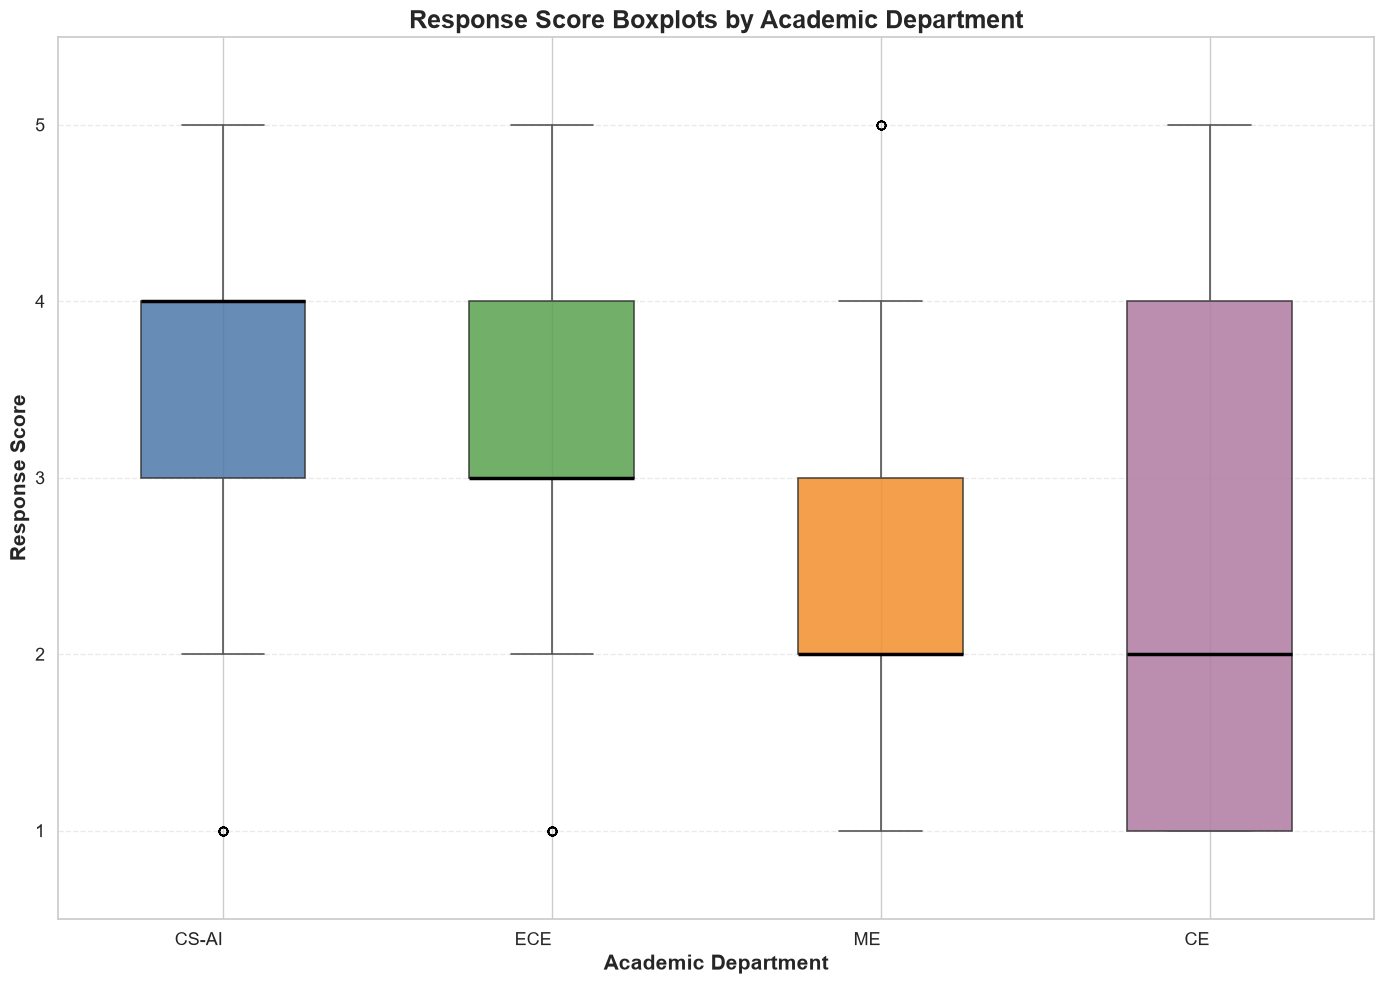

,Academic Department,Median,Bottom-Two-Box (%),Top-Two-Box (%)
0,CS-AI,4.0,12.71,69.68
1,ECE,3.0,24.61,42.97
2,ME,2.0,53.90,19.48
3,CE,2.0,52.53,36.36


In [66]:
# Analysis of response distributions by academic department

department_df = df.drop(index="Total")
department_score_columns = [
    "1 (Ext. Dissat.)",
    "2 (Dissat.)",
    "3 (Neutral)",
    "4 (Satisfied)",
    "5 (Ext. Sat.)"
]
department_scores = np.arange(1, 6)

# 1. Histograms/frequency bar charts
fig, axes = plt.subplots(1,4, figsize=(14, 6.1), sharey=False)
axes = axes.ravel()

for ax, (department, row) in zip(axes, department_df.iterrows()):
    counts = row[department_score_columns].to_numpy(dtype=int)

    bars = ax.bar(
        department_scores,
        counts,
        color="steelblue",
        edgecolor="black"
    )

    ax.bar_label(bars, padding=3)
    ax.set_title(department)
    ax.set_xlabel("Response Score")
    ax.set_ylabel("Frequency")
    ax.set_xticks(department_scores)
    ax.set_xticklabels([
        "1\nExt. Dis.", "2\nDis.", "3\nNeutral",
        "4\nSat.", "5\nExt. Sat."
    ])
    # ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.grid(False)

    # Reduce the y-axis scale for the bottom two histograms
    if ax in axes[2:]:
        ax.set_ylim(0, max(counts) * 1.25)
        # Apply a red-to-green gradient to the five bars in every subplot
        gradient_colors = plt.cm.RdYlGn(np.linspace(0, 1, len(department_scores)))

        for ax in axes:
            for bar, color in zip(ax.patches, gradient_colors):
                bar.set_facecolor(color)
                bar.set_edgecolor("black")

fig.suptitle(
    "Response Distribution by Academic Department",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# 2. Percentage and cumulative percentage tables
department_percentage_tables = {}

for department, row in department_df.iterrows():
    counts = row[department_score_columns].astype(int)
    total = counts.sum()
    percentages = counts / total * 100

    department_table = pd.DataFrame({
        "Response Category": department_score_columns,
        "Count": counts.to_numpy(),
        "Percentage (%)": percentages.round(2),
        "Cumulative Percentage (%)": percentages.cumsum().round(2)
    },index=None)

    department_percentage_tables[department] = department_table

    print(f"\n{department}")
    # reset the index to start from 1 for display purposes
    department_table.reset_index(drop=True, inplace=True)
    display(department_table)


# 3. Create expanded response arrays
department_responses = {
    department: np.repeat(
        department_scores,
        row[department_score_columns].to_numpy(dtype=int)
    )
    for department, row in department_df.iterrows()
}


# 4. Boxplots for all four departments
fig, ax = plt.subplots(figsize=(14, 10))

department_boxplot = ax.boxplot(
    list(department_responses.values()),
    tick_labels=list(department_responses.keys()),
    patch_artist=True,
    widths=0.5
)

box_colors = ["#4C78A8", "#59A14F", "#F28E2B", "#B07AA1"]

for box, color in zip(department_boxplot["boxes"], box_colors):
    box.set_facecolor(color)
    box.set_alpha(0.85)
    box.set_edgecolor("#333333")
    box.set_linewidth(1.2)

for median in department_boxplot["medians"]:
    median.set_color("black")
    median.set_linewidth(2.5)

for whisker in department_boxplot["whiskers"]:
    whisker.set_color("#555555")
    whisker.set_linewidth(1.2)

for cap in department_boxplot["caps"]:
    cap.set_color("#555555")
    cap.set_linewidth(1.2)

ax.set_title(
    "Response Score Boxplots by Academic Department",
    fontsize=18,
    fontweight="bold"
)
ax.set_xlabel(
    "Academic Department",
    fontsize=15,
    fontweight="bold",
)
ax.set_ylabel(
    "Response Score",
    fontsize=15,
    fontweight="bold"
)
ax.tick_params(axis="both", labelsize=13)
ax.set_ylim(0.5, 5.5)
ax.set_yticks(department_scores)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=0, ha="right")
plt.tight_layout()
plt.show()


# 5. Median, IQR, Bottom-Two-Box, and Top-Two-Box statistics
department_summary = pd.DataFrame({
    "Academic Department": list(department_responses.keys()),
    "Median": [
        np.median(responses)
        for responses in department_responses.values()
    ],
    # "IQR": [
    #     np.percentile(responses, 75) - np.percentile(responses, 25)
    #     for responses in department_responses.values()
    # ],
    "Bottom-Two-Box (%)": [
        np.mean(responses <= 2) * 100
        for responses in department_responses.values()
    ],
    "Top-Two-Box (%)": [
        np.mean(responses >= 4) * 100
        for responses in department_responses.values()
    ]
})

department_summary[
    ["Median", "Bottom-Two-Box (%)", "Top-Two-Box (%)"]
] = department_summary[
    ["Median", "Bottom-Two-Box (%)", "Top-Two-Box (%)"]
].round(2)

display(department_summary)

In [32]:
# Calculate Leik's and Blair-Lacy's indices by academic department

department_dispersion = pd.DataFrame({
    "Academic Department": department_df.index,
    "Leik's Index (D)": [
        leiks_index(row[department_score_columns])
        for _, row in department_df.iterrows()
    ],
    "Blair-Lacy's Index (D_bl)": [
        blair_lacy_index(row[department_score_columns])
        for _, row in department_df.iterrows()
    ]
})

department_dispersion[
    ["Leik's Index (D)", "Blair-Lacy's Index (D_bl)"]
] = department_dispersion[
    ["Leik's Index (D)", "Blair-Lacy's Index (D_bl)"]
].round(4)

display(department_dispersion)

,Academic Department,Leik's Index (D),Blair-Lacy's Index (D_bl)
0,CS-AI,0.3582,0.5458
1,ECE,0.4355,0.6063
2,ME,0.4838,0.6542
3,CE,0.7121,0.8850


In [34]:
import pandas as pd

# Define the table data
data = {
    "Entrance Rank Tier": [
        "Top Quartile", 
        "Second Quartile", 
        "Third Quartile", 
        "Bottom Quartile", 
        "Total"
    ],
    "Grade A":[67, 27, 11, 6, 111],
    "Grade B":[26, 48, 26, 14, 114],
    "Grade C":[9, 21, 47, 33, 110],
    "Grade D":[2, 11, 21, 46, 80],
    "Total": [104, 107, 105, 99, 415]
}

# Create the DataFrame
df = pd.DataFrame(data)

# Set the tier column as index (optional)
df.set_index("Entrance Rank Tier", inplace=True)

df


,Grade A,Grade B,Grade C,Grade D,Total
Entrance Rank Tier,,,,,
Top Quartile,67,26,9,2,104
Second Quartile,27,48,21,11,107
Third Quartile,11,26,47,21,105
Bottom Quartile,6,14,33,46,99
Total,111,114,110,80,415


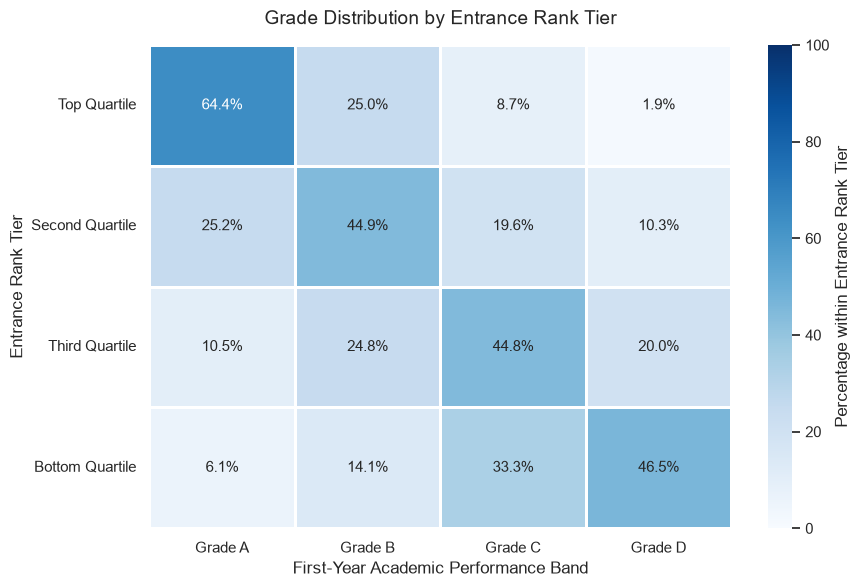

In [36]:
# 4×4 row-percentage heatmap of grade distribution by entrance-rank tier

observed = df.loc[df.index != "Total", grade_columns]

row_percentages = observed.div(observed.sum(axis=1), axis=0) * 100
annotations = row_percentages.map(lambda value: f"{value:.1f}%")

plt.figure(figsize=(9, 6))

sns.heatmap(
    row_percentages,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Percentage within Entrance Rank Tier"}
)

plt.title("Grade Distribution by Entrance Rank Tier", fontsize=14, pad=15)
plt.xlabel("First-Year Academic Performance Band")
plt.ylabel("Entrance Rank Tier")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [7]:
# Convert the contingency table into individual paired observations
from itertools import combinations
#import counter
from collections import Counter

pairwise_observations = pd.DataFrame({
    "Entrance Rank": entrance_rank,
    "Grade Score": grade_score
})

# Create all pairwise comparisons
pairwise_rows = []

for (i, obs_i), (j, obs_j) in combinations(
    pairwise_observations.iterrows(), 2
):
    dx = obs_i["Entrance Rank"] - obs_j["Entrance Rank"]
    dy = obs_i["Grade Score"] - obs_j["Grade Score"]

    if dx == 0 or dy == 0:
        relation = "Tied"
    elif dx * dy > 0:
        relation = "Concordant"
    else:
        relation = "Discordant"

    pairwise_rows.append({
        "Observation 1": i,
        "Observation 2": j,
        "Entrance Rank 1": obs_i["Entrance Rank"],
        "Entrance Rank 2": obs_j["Entrance Rank"],
        "Grade 1": obs_i["Grade Score"],
        "Grade 2": obs_j["Grade Score"],
        "Relation": relation
    })

pairwise_df = pd.DataFrame(pairwise_rows)

display(pairwise_df.head())

# Calculate concordant and discordant pairs
concordant = (pairwise_df["Relation"] == "Concordant").sum()
discordant = (pairwise_df["Relation"] == "Discordant")

discordant = discordant.sum()

# Tie correction terms
x_counts = Counter(entrance_rank.tolist())
y_counts = Counter(grade_score.tolist())

T_x = sum(k * (k - 1) / 2 for k in x_counts.values())
T_y = sum(k * (k - 1) / 2 for k in y_counts.values())

n = len(entrance_rank)
total_pairs = n * (n - 1) / 2

denominator = np.sqrt(
    (total_pairs - T_x) * (total_pairs - T_y)
)

tau_b_formula = (
    (concordant - discordant) / denominator
    if denominator != 0 else 0
)

print(f"Total observations: {n}")
print(f"Total pairs: {int(total_pairs):,}")
print(f"Concordant pairs: {concordant:,}")
print(f"Discordant pairs: {discordant:,}")
print(f"Entrance-rank ties: {T_x:,.0f}")
print(f"Grade ties: {T_y:,.0f}")
print(f"Kendall's tau-b: {tau_b_formula:.4f}")

,Observation 1,Observation 2,Entrance Rank 1,Entrance Rank 2,Grade 1,Grade 2,Relation
0,0,1,1,1,1,1,Tied
1,0,2,1,1,1,1,Tied
2,0,3,1,1,1,1,Tied
3,0,4,1,1,1,1,Tied
4,0,5,1,1,1,1,Tied


Total observations: 415
Total pairs: 85,905
Concordant pairs: 41,996
Discordant pairs: 8,527
Entrance-rank ties: 21,338
Grade ties: 21,701
Kendall's tau-b: 0.5198


In [35]:
from scipy.stats import kendalltau
import numpy as np

tier_order = [
    "Top Quartile",
    "Second Quartile",
    "Third Quartile",
    "Bottom Quartile"
]
grade_columns = ["Grade A", "Grade B", "Grade C", "Grade D"]

observed = df.loc[tier_order, grade_columns]
counts = observed.to_numpy(dtype=int)

# Expand entrance-rank tiers by row totals
entrance_rank = np.repeat(
    np.arange(1, len(tier_order) + 1),
    counts.sum(axis=1)
)

# Expand grades within each entrance-rank tier
grade_score = np.concatenate([
    np.repeat(np.arange(1, len(grade_columns) + 1), row_counts)
    for row_counts in counts
])

tau_b, p_value = kendalltau(entrance_rank, grade_score)

print(f"Kendall's tau-b: {tau_b:.4f}")
print(f"P-value: {p_value:.6f}")

if tau_b > 0:
    print(
        "There is a positive association: lower entrance-rank tiers "
        "are associated with lower grade codes."
    )
else:
    print(
        "There is a negative association: higher entrance-rank tiers "
        "are associated with higher grade codes."
    )

Kendall's tau-b: 0.5198
P-value: 0.000000
There is a positive association: lower entrance-rank tiers are associated with lower grade codes.


In [48]:
from scipy.stats import chi2_contingency
entrance_df = df.drop(index="Total").copy()

# Grade order: A = 1 (highest) through D = 4 (lowest)
grade_columns = ["Grade A", "Grade B", "Grade C", "Grade D"]
grade_scores = np.arange(1, 5)
grade_labels = ["A", "B", "C", "D"]
observed = entrance_df[grade_columns]

chi_square, p_value, degrees_of_freedom, expected = chi2_contingency(observed)

expected_df = pd.DataFrame(
    expected,
    index=observed.index,
    columns=observed.columns
)

print(f"Chi-square statistic: {chi_square:.4f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"P-value: {p_value:.6f}")

print("\nExpected frequencies:")
display(expected_df.round(2))

Chi-square statistic: 188.2984
Degrees of freedom: 9
P-value: 0.000000

Expected frequencies:


,Grade A,Grade B,Grade C,Grade D
Entrance Rank Tier,,,,
Top Quartile,27.82,28.57,27.57,20.05
Second Quartile,28.62,29.39,28.36,20.63
Third Quartile,28.08,28.84,27.83,20.24
Bottom Quartile,26.48,27.20,26.24,19.08


In [ ]:
#how can i comment whether incoming entrance rank tiers reliably predict first-year collegiate academic performance bands

In [ ]:
# Analysis by Entrance Rank Tier and Grade



# 1. Frequency distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharey=False)
axes = axes.ravel()

for ax, (tier, row) in zip(axes, entrance_df.iterrows()):
    counts = row[grade_columns].to_numpy(dtype=int)

    bars = ax.bar(
        grade_labels,
        counts,
        color="steelblue",
        edgecolor="black"
    )
    ax.bar_label(bars, padding=3)

    ax.set_title(tier)
    ax.set_xlabel("Grade")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle(
    "Grade Distribution by Entrance Rank Tier",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


# 2. Percentage and cumulative percentage tables
entrance_percentage_tables = {}

for tier, row in entrance_df.iterrows():
    counts = row[grade_columns].astype(int)
    total = counts.sum()
    percentages = counts / total * 100

    tier_table = pd.DataFrame({
        "Grade": grade_labels,
        "Count": counts.to_numpy(),
        "Percentage (%)": percentages.to_numpy().round(2),
        "Cumulative Percentage (%)": percentages.cumsum().to_numpy().round(2)
    }).reset_index(drop=True)

    entrance_percentage_tables[tier] = tier_table

    print(f"\n{tier}")
    display(tier_table)


# 3. Expanded grade-response arrays
entrance_responses = {
    tier: np.repeat(
        grade_scores,
        row[grade_columns].to_numpy(dtype=int)
    )
    for tier, row in entrance_df.iterrows()
}


# 4. Box plots
fig, ax = plt.subplots(figsize=(12, 7))

entrance_boxplot = ax.boxplot(
    list(entrance_responses.values()),
    tick_labels=list(entrance_responses.keys()),
    patch_artist=True,
    widths=0.5
)

for box in entrance_boxplot["boxes"]:
    box.set_facecolor("steelblue")
    box.set_alpha(0.75)

ax.set_title("Grade Boxplots by Entrance Rank Tier")
ax.set_xlabel("Entrance Rank Tier")
ax.set_ylabel("Grade Score")
ax.set_ylim(0.5, 4.5)
ax.set_yticks(grade_scores)
ax.set_yticklabels(grade_labels)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


# 5. Comparative metrics
entrance_summary = pd.DataFrame({
    "Entrance Rank Tier": list(entrance_responses.keys()),
    "Median": [
        np.median(values)
        for values in entrance_responses.values()
    ],
    "IQR": [
        np.percentile(values, 75) - np.percentile(values, 25)
        for values in entrance_responses.values()
    ],
    "Lower-Two-Grade (%)": [
        np.mean(values >= 3) * 100
        for values in entrance_responses.values()
    ],
    "Upper-Two-Grade (%)": [
        np.mean(values <= 2) * 100
        for values in entrance_responses.values()
    ]
})

metric_columns = [
    "Median",
    "IQR",
    "Lower-Two-Grade (%)",
    "Upper-Two-Grade (%)"
]

entrance_summary[metric_columns] = entrance_summary[metric_columns].round(2)

display(entrance_summary)


# 6. Dispersion metrics
entrance_dispersion = pd.DataFrame({
    "Entrance Rank Tier": entrance_df.index,
    "Leik's Index (D)": [
        leiks_index(row[grade_columns])
        for _, row in entrance_df.iterrows()
    ],
    "Blair-Lacy's Index (D_bl)": [
        blair_lacy_index(row[grade_columns])
        for _, row in entrance_df.iterrows()
    ]
})

entrance_dispersion[
    ["Leik's Index (D)", "Blair-Lacy's Index (D_bl)"]
] = entrance_dispersion[
    ["Leik's Index (D)", "Blair-Lacy's Index (D_bl)"]
].round(4)

display(entrance_dispersion)

KeyError: "['Total'] not found in axis"

Q1: 17.0
Q2 (Median): 43.0
Q3: 62.0
Minimum: 7
Maximum: 222


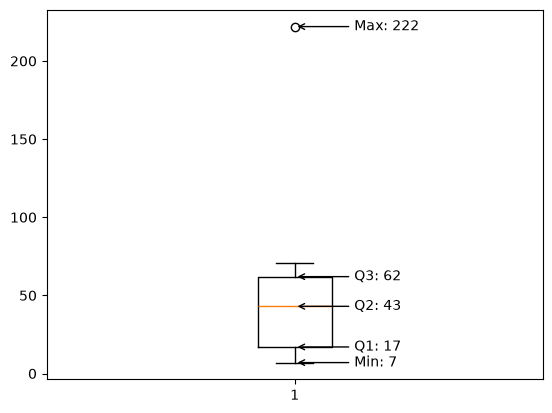

In [25]:
a=[12, 7, 22, 43, 222, 71, 53]
plt.boxplot(a)
q1, q2, q3 = np.percentile(a, [25, 50, 75])
minimum, maximum = np.min(a), np.max(a)

print(f"Q1: {q1}")
print(f"Q2 (Median): {q2}")
print(f"Q3: {q3}")
print(f"Minimum: {minimum}")
print(f"Maximum: {maximum}")

ax = plt.gca()

for value, label in [
    (minimum, "Min"),
    (q1, "Q1"),
    (q2, "Q2"),
    (q3, "Q3"),
    (maximum, "Max")
]:
    ax.annotate(
        f"{label}: {value:g}",
        xy=(1, value),
        xytext=(1.12, value),
        va="center",
        arrowprops={"arrowstyle": "->"}
    )

plt.show()

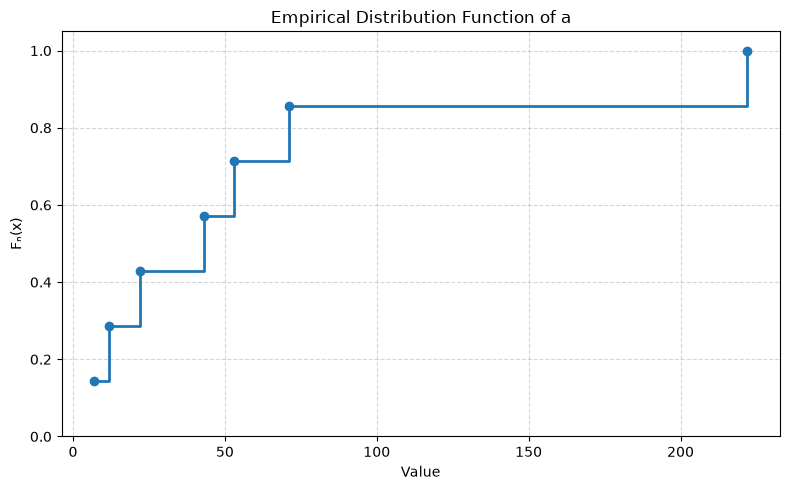

In [26]:
# Empirical distribution function (ECDF) for a

a_sorted = np.sort(a)
n = len(a)
ecdf_values = np.arange(1, n + 1) / n

plt.figure(figsize=(8, 5))
plt.step(a_sorted, ecdf_values, where="post", linewidth=2, color="tab:blue")
plt.scatter(a_sorted, ecdf_values, color="tab:blue", zorder=3)

plt.xlabel("Value")
plt.ylabel("Fₙ(x)")
plt.title("Empirical Distribution Function of a")
plt.ylim(0, 1.05)
plt.yticks(np.linspace(0, 1, 6))
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
import numpy as np


a=[12, 7, 22, 43, 222, 71, 53]

print(np.median(a))
print(np.mean(a))

def mad(a,x):
    mad=0
    for i in a:
        mad+=(np.abs(i-x))
    return mad/len(a)


def msd(a,x):
    msd=0
    for i in a:
        msd+=((i-x)**2)
    return msd/len(a)

43.0
61.42857142857143


In [13]:
X_mad=[]
Y_mad=[]
X_msd=[]
Y_msd=[]

for i in a:
    print(i,mad(a,i))
    X_mad.append(i)
    Y_mad.append(mad(a,i))

for i in a:
    print(i,msd(a,i))
    X_msd.append(i)
    Y_msd.append(msd(a,i))

12 50.857142857142854
7 54.42857142857143
22 46.57142857142857
43 43.57142857142857
222 160.57142857142858
71 52.714285714285715
53 45.0
12 7192.571428571428
7 7711.857142857143
22 6304.0
43 5089.0
222 30532.571428571428
71 4841.0
53 4820.428571428572


In [16]:
order_mad = np.argsort(X_mad)
X_mad = [X_mad[i] for i in order_mad]
Y_mad = [Y_mad[i] for i in order_mad]

print(X_mad)
print(Y_mad)

# 
order_msd = np.argsort(X_msd)
X_msd = [X_msd[i] for i in order_msd]
Y_msd = [Y_msd[i] for i in order_msd]

print(X_msd)
print(Y_msd)

[7, 12, 22, 43, 53, 71, 222]
[np.float64(54.42857142857143), np.float64(50.857142857142854), np.float64(46.57142857142857), np.float64(43.57142857142857), np.float64(45.0), np.float64(52.714285714285715), np.float64(160.57142857142858)]
[7, 12, 22, 43, 53, 71, 222]
[7711.857142857143, 7192.571428571428, 6304.0, 5089.0, 4820.428571428572, 4841.0, 30532.571428571428]


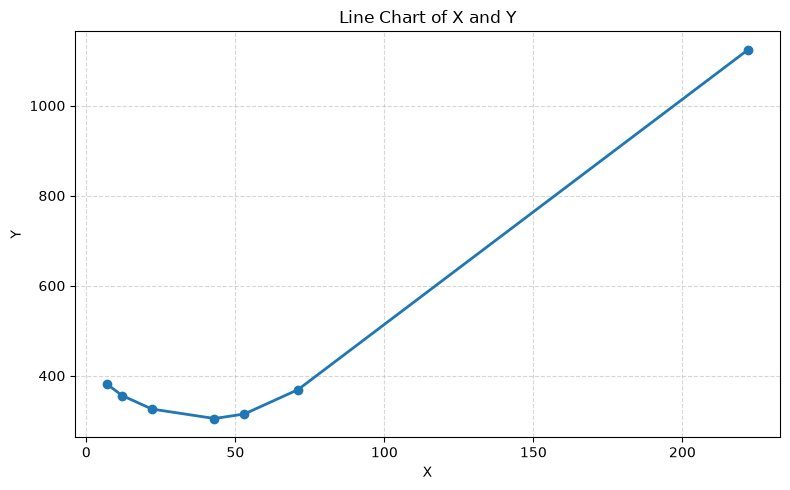

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(X, Y, marker="o", linewidth=2, color="tab:blue")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Line Chart of X and Y")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

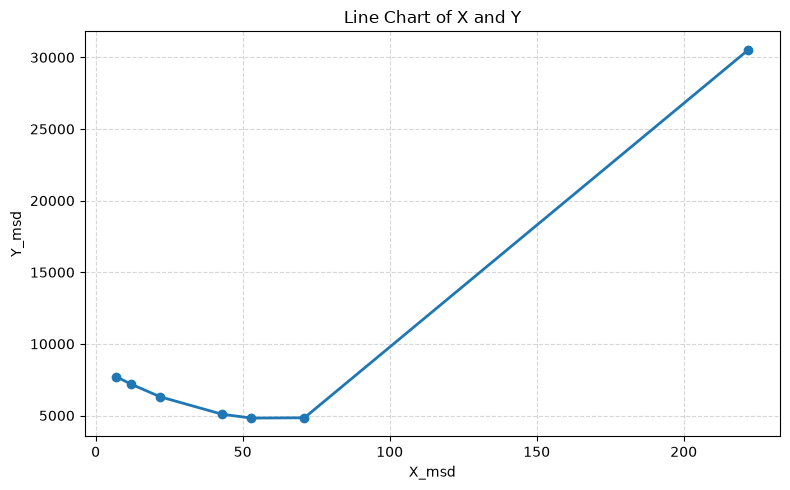

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(X_msd, Y_msd, marker="o", linewidth=2, color="tab:blue")

plt.xlabel("X_msd")
plt.ylabel("Y_msd")
plt.title("Line Chart of X and Y")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

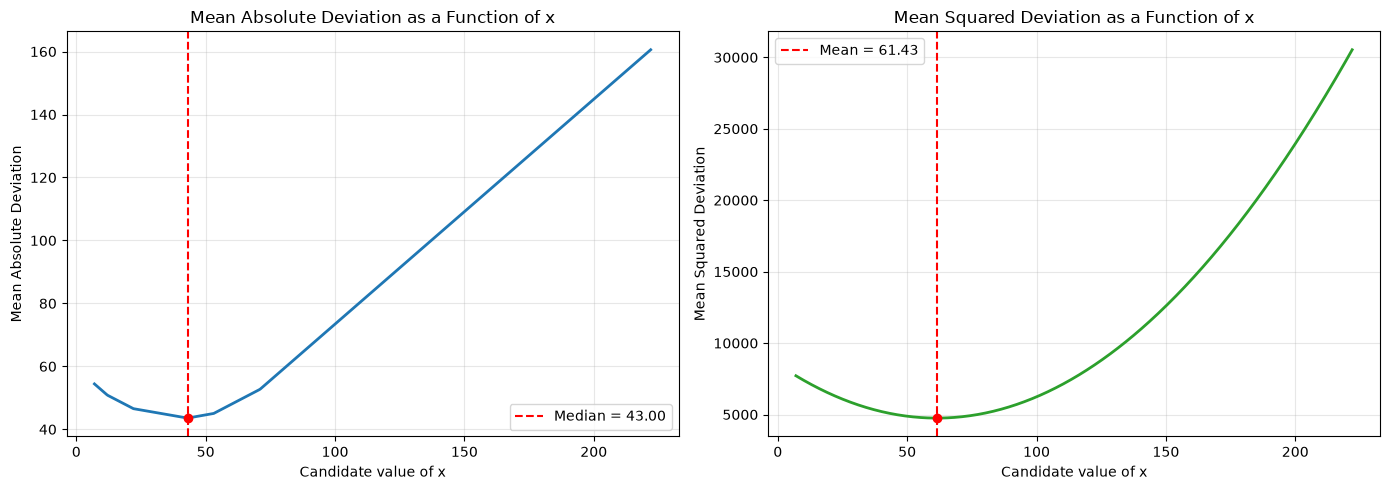

MAD is minimized at the median: x = 43.00
MSD is minimized at the mean: x = 61.43


In [18]:
# Candidate x-values across the full data range
x_grid = np.linspace(min(a), max(a), 500)

# Calculate MAD and MSD for every candidate x
mad_values = np.array([
    np.mean(np.abs(np.asarray(a) - x))
    for x in x_grid
])

msd_values = np.array([
    np.mean((np.asarray(a) - x) ** 2)
    for x in x_grid
])

median_a = np.median(a)
mean_a = np.mean(a)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Mean Absolute Deviation
axes[0].plot(x_grid, mad_values, color="tab:blue", linewidth=2)
axes[0].axvline(median_a, color="red", linestyle="--",
                label=f"Median = {median_a:.2f}")
axes[0].scatter(
    median_a,
    np.mean(np.abs(np.asarray(a) - median_a)),
    color="red",
    zorder=3
)
axes[0].set_title("Mean Absolute Deviation as a Function of x")
axes[0].set_xlabel("Candidate value of x")
axes[0].set_ylabel("Mean Absolute Deviation")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Mean Squared Deviation
axes[1].plot(x_grid, msd_values, color="tab:green", linewidth=2)
axes[1].axvline(mean_a, color="red", linestyle="--",
                label=f"Mean = {mean_a:.2f}")
axes[1].scatter(
    mean_a,
    np.mean((np.asarray(a) - mean_a) ** 2),
    color="red",
    zorder=3
)
axes[1].set_title("Mean Squared Deviation as a Function of x")
axes[1].set_xlabel("Candidate value of x")
axes[1].set_ylabel("Mean Squared Deviation")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"MAD is minimized at the median: x = {median_a:.2f}")
print(f"MSD is minimized at the mean: x = {mean_a:.2f}")

In [19]:
# Derive the MSD equation: MSD(x) = Ax^2 + Bx + C
a_array = np.asarray(a, dtype=float)

A = 1
B = -2 * np.mean(a_array)
C = np.mean(a_array ** 2)

print(f"MSD(x) = {A:.4f}x² + ({B:.4f})x + {C:.4f}")
print(f"MSD(x) = x² - {abs(B):.4f}x + {C:.4f}")

# Verify using a polynomial fit
coefficients = np.polyfit(x_grid, msd_values, 2)
print("Fitted coefficients:", coefficients)

MSD(x) = 1.0000x² + (-122.8571)x + 8522.8571
MSD(x) = x² - 122.8571x + 8522.8571
Fitted coefficients: [ 1.00000000e+00 -1.22857143e+02  8.52285714e+03]


In [20]:
61.43*61.43 - 122.8571*61.43 + 8522.8571

4749.390346999999

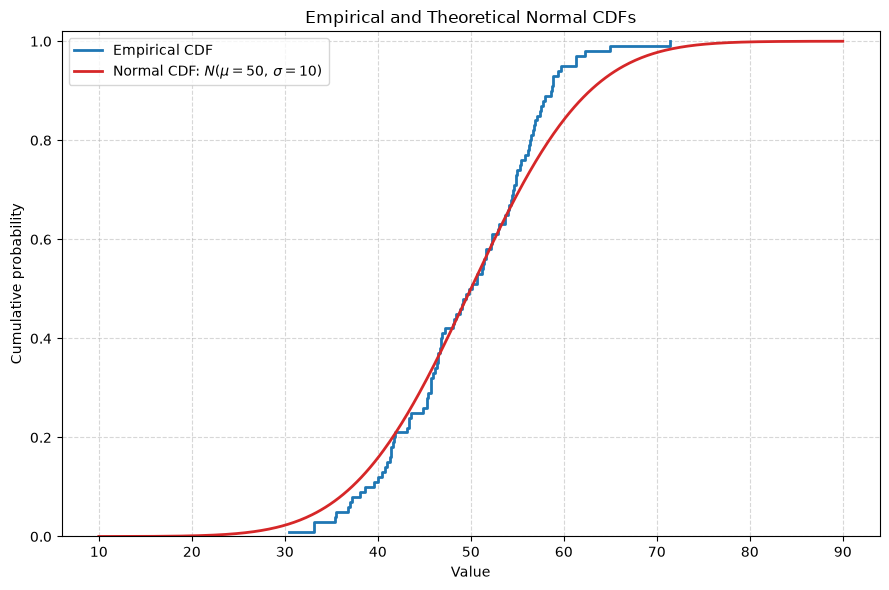

In [11]:
from scipy.stats import norm
import matplotlib.pyplot as plt
# Generate 100 observations from N(mu, sigma²)
mu, sigma = 50, 10
rng = np.random.default_rng(42)
sample = rng.normal(loc=mu, scale=sigma, size=100)

# Empirical distribution function
sample_sorted = np.sort(sample)
ecdf = np.arange(1, len(sample_sorted) + 1) / len(sample_sorted)

# Theoretical CDF of N(mu, sigma²)
x_grid = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 500)
normal_cdf = norm.cdf(x_grid, loc=mu, scale=sigma)

plt.figure(figsize=(9, 6))
plt.step(sample_sorted, ecdf, where="post", label="Empirical CDF", linewidth=2)
plt.plot(
    x_grid, normal_cdf,
    label=rf"Normal CDF: $N(\mu={mu},\,\sigma={sigma})$",
    color="tab:red",
    linewidth=2
)

plt.xlabel("Value")
plt.ylabel("Cumulative probability")
plt.title("Empirical and Theoretical Normal CDFs")
plt.ylim(0, 1.02)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

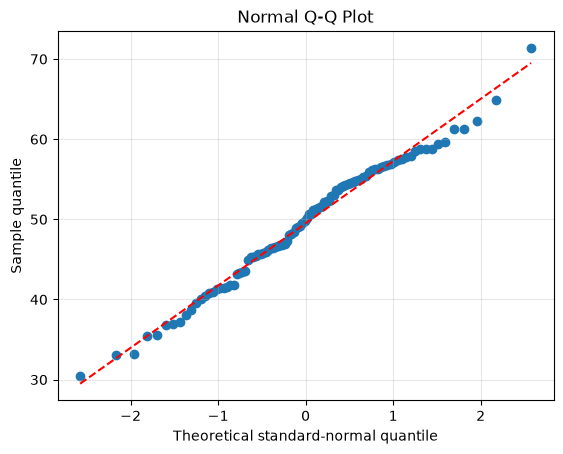

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

values = np.asarray(sample, dtype=float)  # use the sample from your CDF plot
sample_quantiles = np.sort(values)

n = len(sample_quantiles)
probabilities = (np.arange(1, n + 1) - 0.5) / n
normal_quantiles = norm.ppf(probabilities)  # standard normal: mean 0, std 1

plt.scatter(normal_quantiles, sample_quantiles)
plt.xlabel("Theoretical standard-normal quantile")
plt.ylabel("Sample quantile")
plt.title("Normal Q-Q Plot")

# Reference line if using the sample mean and standard deviation
line_x = np.array([normal_quantiles.min(), normal_quantiles.max()])
plt.plot(line_x, values.mean() + values.std(ddof=1) * line_x, "r--")

plt.grid(True, alpha=0.3)
plt.show()

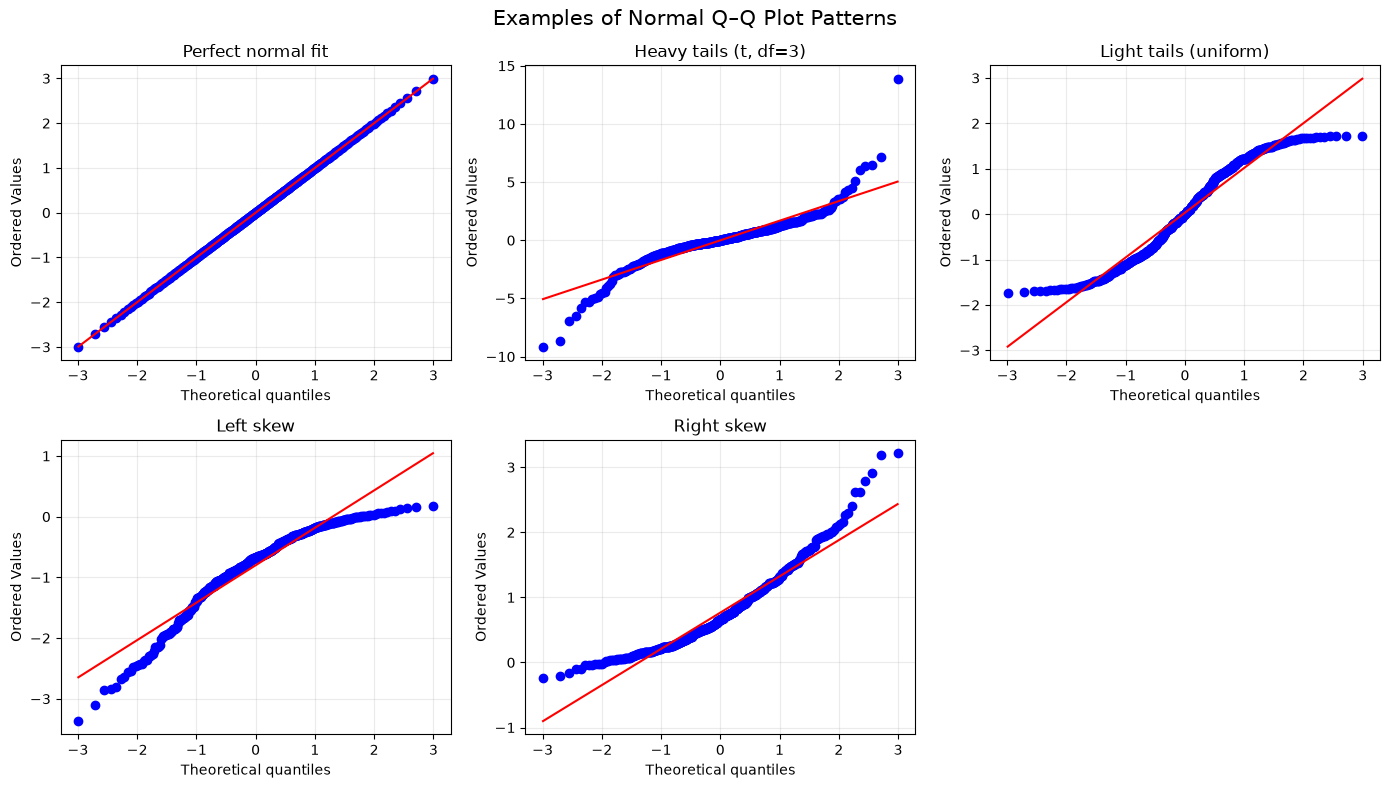

In [13]:
from scipy import stats

rng = np.random.default_rng(42)
n = 500

# Construct values that match the normal Q–Q plot's theoretical quantiles
theoretical_q, _ = stats.probplot(np.zeros(n), dist="norm", fit=False)
examples = {
    "Perfect normal fit": theoretical_q,
    "Heavy tails (t, df=3)": rng.standard_t(df=3, size=n),
    "Light tails (uniform)": rng.uniform(-np.sqrt(3), np.sqrt(3), size=n),
    "Left skew": stats.skewnorm.rvs(a=-8, size=n, random_state=rng),
    "Right skew": stats.skewnorm.rvs(a=8, size=n, random_state=rng),
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, (title, values) in zip(axes, examples.items()):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set_title(title)
    ax.grid(alpha=0.25)

# Hide the unused sixth panel
axes[-1].axis("off")

fig.suptitle("Examples of Normal Q–Q Plot Patterns", fontsize=15)
plt.tight_layout()
plt.show()

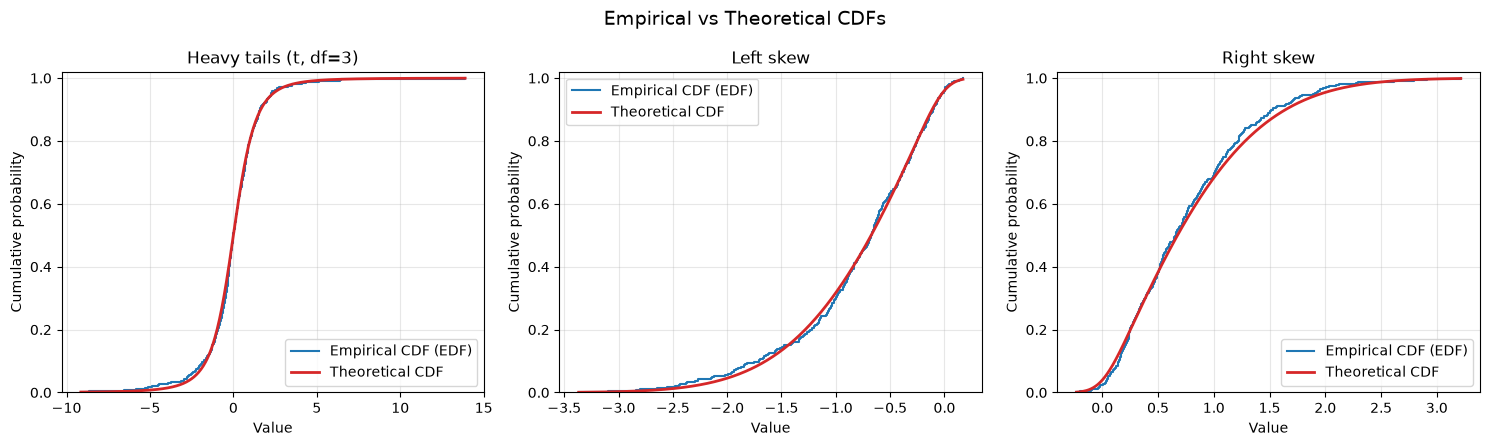

In [14]:
# Compare each sample's empirical distribution function (EDF) with its
# corresponding theoretical CDF.

distributions = {
    "Heavy tails (t, df=3)": stats.t(df=3),
    "Left skew": stats.skewnorm(a=-8),
    "Right skew": stats.skewnorm(a=8),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (label, distribution) in zip(axes, distributions.items()):
    values = np.sort(examples[label])
    n = len(values)
    edf = np.arange(1, n + 1) / n

    x_grid = np.linspace(values.min(), values.max(), 500)

    ax.step(values, edf, where="post", label="Empirical CDF (EDF)")
    ax.plot(
        x_grid,
        distribution.cdf(x_grid),
        color="tab:red",
        linewidth=2,
        label="Theoretical CDF"
    )
    ax.set_title(label)
    ax.set_xlabel("Value")
    ax.set_ylabel("Cumulative probability")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Empirical vs Theoretical CDFs", fontsize=14)
plt.tight_layout()
plt.show()

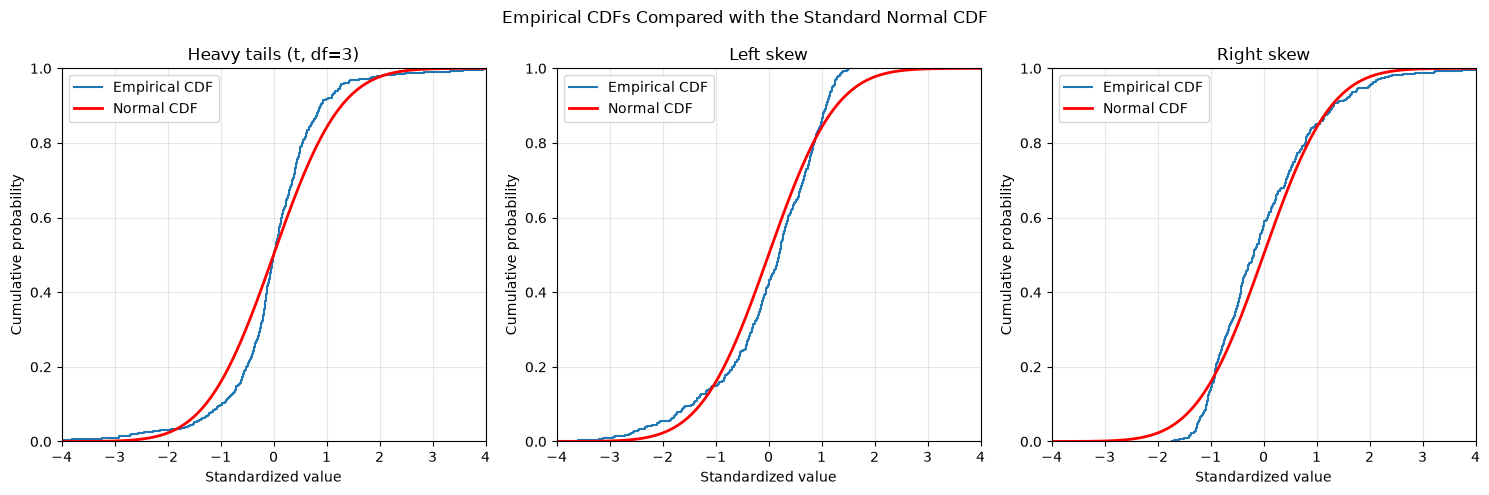

In [16]:
distributions = {
    "Heavy tails (t, df=3)": examples["Heavy tails (t, df=3)"],
    "Left skew": examples["Left skew"],
    "Right skew": examples["Right skew"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

x_grid = np.linspace(-4, 4, 500)
normal_cdf = stats.norm.cdf(x_grid)

for ax, (label, data) in zip(axes, distributions.items()):
    # Standardize the sample for comparison with N(0, 1)
    z = (data - np.mean(data)) / np.std(data, ddof=1)
    z_sorted = np.sort(z)
    empirical_cdf = np.arange(1, len(z_sorted) + 1) / len(z_sorted)

    ax.step(z_sorted, empirical_cdf, where="post", label="Empirical CDF")
    ax.plot(x_grid, normal_cdf, color="red", linewidth=2, label="Normal CDF")
    ax.set_title(label)
    ax.set_xlabel("Standardized value")
    ax.set_ylabel("Cumulative probability")
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Empirical CDFs Compared with the Standard Normal CDF")
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
activites=pd.read_csv(r"C:\Users\Nishad\Downloads\Activities (3).csv")

In [10]:
activities = activities.loc[activities["Distance"] <= 50].copy()

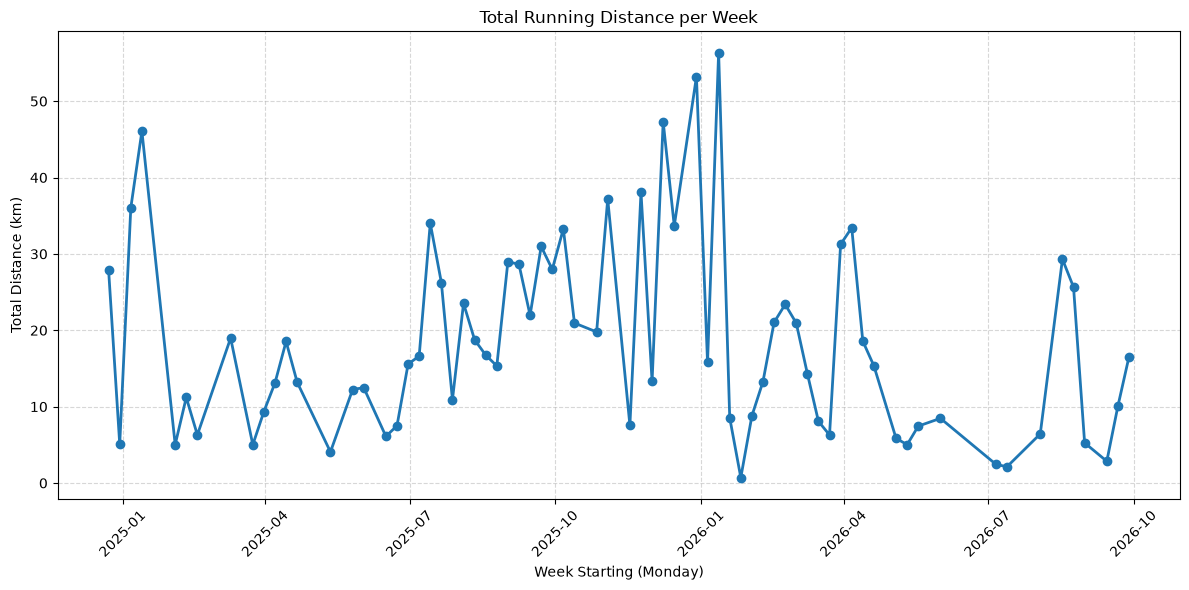

In [11]:
# Group activities into Monday–Sunday weeks, anchored on 23 December 2024
import matplotlib.pyplot as plt
activities_weekly = activities.copy()
activities_weekly["Date"] = pd.to_datetime(activities_weekly["Date"])
activities_weekly["Distance"] = pd.to_numeric(activities_weekly["Distance"], errors="coerce")

anchor = pd.Timestamp("2024-12-23")
days_from_anchor = (activities_weekly["Date"].dt.normalize() - anchor).dt.days
activities_weekly["Week Start"] = anchor + pd.to_timedelta(
    (days_from_anchor // 7) * 7, unit="D"
)

weekly_distance = (
    activities_weekly.groupby("Week Start")["Distance"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(weekly_distance.index, weekly_distance.values, marker="o", linewidth=2)
plt.title("Total Running Distance per Week")
plt.xlabel("Week Starting (Monday)")
plt.ylabel("Total Distance (km)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
weekly_distance.describe().round(2)

count    71.00
mean     18.34
std      12.78
min       0.71
25%       7.82
50%      15.56
75%      27.04
max      56.36
Name: Distance, dtype: float64

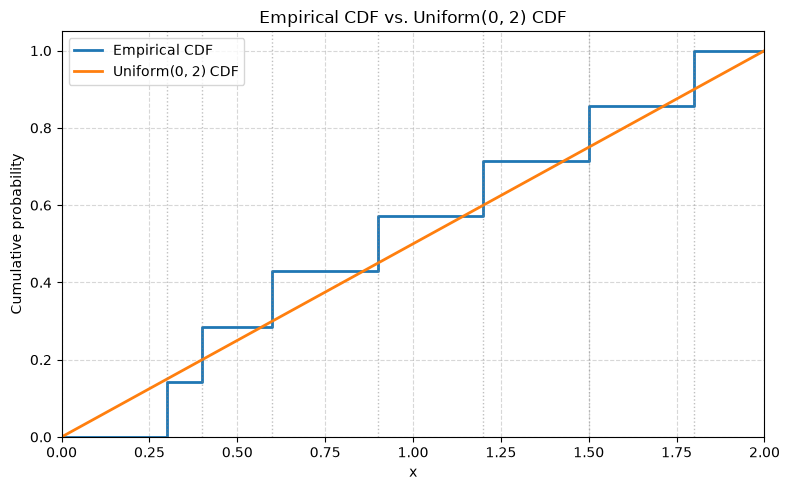

In [4]:
import numpy as np
import matplotlib.pyplot as plt
values = np.array([0.3, 0.9, 0.4, 0.6, 1.8, 1.5, 1.2])
sorted_values = np.sort(values)
n = len(sorted_values)

# Empirical CDF step coordinates
ecdf_x = np.concatenate(([0], sorted_values, [2]))
ecdf_y = np.concatenate(([0], np.arange(1, n + 1) / n, [1]))

# Hypothesized Uniform(0, 2) CDF
x_grid = np.linspace(0, 2, 500)
uniform_cdf = np.clip(x_grid / 2, 0, 1)

plt.figure(figsize=(8, 5))
plt.step(ecdf_x, ecdf_y, where="post", label="Empirical CDF", linewidth=2)
plt.plot(x_grid, uniform_cdf, label="Uniform(0, 2) CDF", linewidth=2)

plt.xlabel("x")
plt.ylabel("Cumulative probability")
plt.title("Empirical CDF vs. Uniform(0, 2) CDF")
plt.xlim(0, 2)
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

for value in sorted_values:
    plt.axvline(value, color="gray", linestyle=":", alpha=0.5, linewidth=1)

plt.show()

In [5]:
theoretical_at_values = np.clip(sorted_values / 2, 0, 1)
empirical_right = np.arange(1, n + 1) / n
empirical_left = np.arange(n) / n

abs_differences = np.abs(empirical_right - theoretical_at_values)
d_plus = np.max(empirical_right - theoretical_at_values)
d_minus = np.max(theoretical_at_values - empirical_left)
ks_statistic = max(d_plus, d_minus)

print("Absolute differences at the observations:")
print(abs_differences.tolist())
print(f"D+ = {d_plus:.6f}")
print(f"D- = {d_minus:.6f}")
print(f"KS statistic = {ks_statistic:.6f}")

Absolute differences at the observations:
[0.007142857142857145, 0.08571428571428569, 0.12857142857142856, 0.12142857142857139, 0.11428571428571432, 0.1071428571428571, 0.09999999999999998]
D+ = 0.128571
D- = 0.150000
KS statistic = 0.150000


In [11]:
for value, cdf_value, edf_value in zip(
    sorted_values, theoretical_at_values, empirical_right
):
    print(
        f"x = {value:.1f}: Uniform(0, 2) CDF = {cdf_value:.4f}, "
        f"EDF = {edf_value:.4f}"
    )

x = 0.3: Uniform(0, 2) CDF = 0.1500, EDF = 0.1429
x = 0.4: Uniform(0, 2) CDF = 0.2000, EDF = 0.2857
x = 0.6: Uniform(0, 2) CDF = 0.3000, EDF = 0.4286
x = 0.9: Uniform(0, 2) CDF = 0.4500, EDF = 0.5714
x = 1.2: Uniform(0, 2) CDF = 0.6000, EDF = 0.7143
x = 1.5: Uniform(0, 2) CDF = 0.7500, EDF = 0.8571
x = 1.8: Uniform(0, 2) CDF = 0.9000, EDF = 1.0000


In [ ]:
Not quite.

For a one-sample KS test, the statistic is:

D = max_x |F_n(x) - F(x)|

where:
- F_n(x) is the EDF
- F(x) is the theoretical CDF

In your output:
- D+ = max(F_n(x) - F(x)) = 0.128571
- D- = max(F(x) - F_n(x)) = 0.15

So the KS statistic is:

D = max(D+, D-) = max(0.128571, 0.15) = 0.15

So:
- 0.1286 is the largest positive gap between EDF and CDF at the plotted points
- 0.15 is the actual KS statistic, because it is the maximum absolute gap over the full curve, not just the positive side

In short: the KS statistic is not 0.1286 here; it is 0.15.

D+ occurs at x = 0.6, gap = 0.1286
D- occurs at x = 0.3, gap = 0.1500
KS statistic = 0.1500


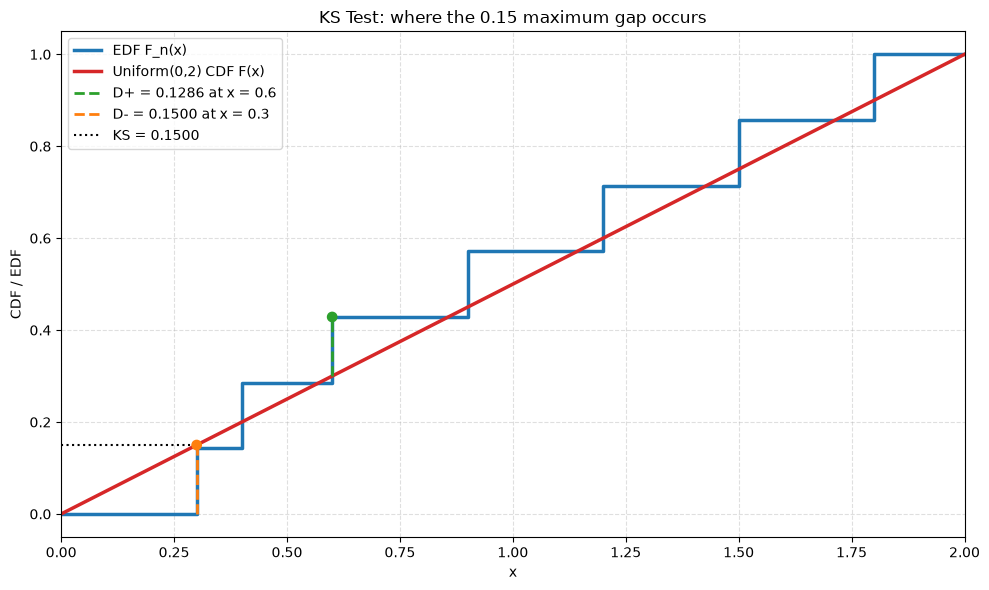

In [12]:
import numpy as np

import matplotlib.pyplot as plt

# Max positive and negative gaps
d_plus_idx = np.argmax(empirical_right - theoretical_at_values)
d_minus_idx = np.argmax(theoretical_at_values - empirical_left)

x_d_plus = sorted_values[d_plus_idx]
x_d_minus = sorted_values[d_minus_idx]

y_edf_plus = empirical_right[d_plus_idx]
y_cdf_plus = theoretical_at_values[d_plus_idx]

y_cdf_minus = theoretical_at_values[d_minus_idx]
y_edf_minus = empirical_left[d_minus_idx]

print(f"D+ occurs at x = {x_d_plus:.1f}, gap = {d_plus:.4f}")
print(f"D- occurs at x = {x_d_minus:.1f}, gap = {d_minus:.4f}")
print(f"KS statistic = {ks_statistic:.4f}")

fig, ax = plt.subplots(figsize=(10, 6))

# EDF and theoretical CDF
ax.step(ecdf_x, ecdf_y, where="post", linewidth=2.5, color="tab:blue", label="EDF F_n(x)")
ax.plot(x_grid, uniform_cdf, linewidth=2.5, color="tab:red", label="Uniform(0,2) CDF F(x)")

# Highlight D+ gap
ax.vlines(
    x_d_plus,
    ymin=y_cdf_plus,
    ymax=y_edf_plus,
    color="tab:green",
    linestyle="--",
    linewidth=2,
    label=f"D+ = {d_plus:.4f} at x = {x_d_plus:.1f}"
)

# Highlight D- gap
ax.vlines(
    x_d_minus,
    ymin=y_edf_minus,
    ymax=y_cdf_minus,
    color="tab:orange",
    linestyle="--",
    linewidth=2,
    label=f"D- = {d_minus:.4f} at x = {x_d_minus:.1f}"
)

# Mark the exact KS maximum
ax.hlines(
    ks_statistic,
    xmin=0,
    xmax=x_d_minus,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label=f"KS = {ks_statistic:.4f}"
)

ax.scatter(
    [x_d_plus, x_d_minus],
    [y_edf_plus, y_cdf_minus],
    color=["tab:green", "tab:orange"],
    s=45,
    zorder=5
)

ax.set_title("KS Test: where the 0.15 maximum gap occurs")
ax.set_xlabel("x")
ax.set_ylabel("CDF / EDF")
ax.set_xlim(0, 2)
ax.set_ylim(-0.05, 1.05)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="best", frameon=True)

plt.tight_layout()
plt.show()